## EDA mới: toàn bộ `train` / `valid` / `test` của TIB — quét cấu trúc đã chạy trên Colab

Notebook này chạy độc lập trên Colab và thay thế phạm vi EDA của cohort 20/70 bài `Lecture` cũ. Chọn **Runtime → Run all**. Phần này đọc mọi dòng ở ba split của creator TIB tại revision đã ghim, không lọc theo `genre`, DOI, tác giả hoặc kích thước mẫu. Khóa từng dòng là `(split, source_index)`; bản ghi thiếu DOI hoặc URL vẫn ở ledger. Mã EDA được nhúng để notebook chạy độc lập trên Colab. Bảng kiểm kê, nhóm chéo split, review reference, hình và kết luận hiển thị trong output; notebook không tạo receipt/CSV/PNG riêng. Lưu notebook kèm output sau khi Run all.

**Ranh giới bằng chứng:** phần mới sẽ đọc nội dung và abstract của `test`; sau khi chạy, split `test` của creator không còn là holdout chưa xem. Nó kiểm tra transcript, timestamp, abstract và metadata keyframe của mọi bản ghi; nó không tải/giải mã video, audio hoặc pixel keyframe và không tự xác nhận abstract là ground truth.

**Bổ sung reference screen:** output cấu trúc bên dưới được giữ từ lần chạy trước; phần sàng lọc nội dung mới ở cuối notebook **chưa chạy**. Chạy lại **Run all** để tạo hash, đối chiếu từ vựng trên transcript đầy đủ và bảng quyết định đồng bộ. Không cần GPU, không chạy mô hình tóm tắt, không xuất file phụ.


In [1]:
import sys, subprocess
try:
    import datasets, pandas, matplotlib
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'datasets', 'pandas', 'matplotlib'])
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

EDA_SOURCE = '"""Pinned all-split TIB metadata and structural cohort scan."""\n\nfrom __future__ import annotations\n\nimport hashlib\nimport json\nimport math\nimport re\nfrom collections import Counter, defaultdict\nfrom datasets import load_dataset\n\nDATASET = "gigant/tib"\nREVISION = "e6ab9fd7c6acd164f3284b8c4b17eb9d94681eee"\nALL_SPLITS = ("train", "valid", "test")\n\n\ndef _word_count(value: object) -> int:\n    return len(str(value or "").split())\n\n\ndef _normalized(value: object) -> str:\n    return " ".join(str(value or "").casefold().split())\n\n\ndef _doi_url_match(doi: object, url: object) -> bool | None:\n    doi_id = re.search(r"10\\.5446/(\\d+)", str(doi or ""))\n    url_id = re.search(r"/media/(\\d+)", str(url or ""))\n    return doi_id.group(1) == url_id.group(1) if doi_id and url_id else None\n\n\ndef _finite_time(value: object) -> bool:\n    return isinstance(value, (int, float)) and not isinstance(value, bool) and math.isfinite(value)\n\n\ndef _scan_split(split: str) -> list[dict]:\n    """Read one pinned creator split and retain compact metadata."""\n    rows = []\n    dataset = load_dataset(DATASET, split=split, revision=REVISION, streaming=True)\n    for index, record in enumerate(dataset):\n        segments = record.get("transcript_segments") or {}\n        starts = (segments.get("start") or []) if isinstance(segments, dict) else []\n        ends = (segments.get("end") or []) if isinstance(segments, dict) else []\n        texts = (segments.get("text") or []) if isinstance(segments, dict) else []\n        aligned = len(starts) == len(ends) == len(texts)\n        numeric_times = all(\n            _finite_time(start) and _finite_time(end)\n            for start, end in zip(starts, ends)\n        )\n        valid_times = aligned and numeric_times and all(\n            start >= 0 and end >= start for start, end in zip(starts, ends)\n        )\n        transcript_words = _word_count(record.get("transcript"))\n        segment_words = sum(_word_count(text) for text in texts)\n        ordered = valid_times and all(starts[i] >= starts[i - 1] for i in range(1, len(starts)))\n        first_start_inversion = next(\n            (\n                {\n                    "previous_segment": i - 1,\n                    "previous_start_seconds": starts[i - 1],\n                    "current_segment": i,\n                    "current_start_seconds": starts[i],\n                }\n                for i in range(1, len(starts))\n                if valid_times and starts[i] < starts[i - 1]\n            ),\n            None,\n        )\n        overlap_count = sum(starts[i] < ends[i - 1] for i in range(1, len(starts))) if ordered else None\n        rows.append(\n            {\n                "source_index": index,\n                "doi": str(record.get("doi") or "").strip(),\n                "title": str(record.get("title") or "").strip(),\n                "genre": str(record.get("genre") or "").strip(),\n                "subject": str(record.get("subject") or "").strip(),\n                "author": str(record.get("author") or "").strip(),\n                "release_year": str(record.get("release_year") or "").strip(),\n                "language": str(record.get("language") or "").strip(),\n                "source_url_present": bool(record.get("url")),\n                "doi_source_url_match": _doi_url_match(record.get("doi"), record.get("url")),\n                "video_url_present": bool(record.get("video_url")),\n                "transcript_words": transcript_words,\n                "segment_text_words": segment_words,\n                "segment_word_ratio": round(segment_words / transcript_words, 3) if transcript_words else None,\n                "abstract_words": _word_count(record.get("abstract")),\n                "segment_count": len(texts),\n                "segments_aligned": aligned,\n                "segments_valid_times": valid_times,\n                "segments_ordered": ordered,\n                "first_start_inversion": first_start_inversion,\n                "segment_overlaps": overlap_count,\n                "empty_segment_texts": sum(not str(text or "").strip() for text in texts),\n                "duration_minutes": max(ends) / 60 if valid_times and ends else None,\n            }\n        )\n    return rows\n\n\ndef scan_all_splits() -> list[dict]:\n    """Scan every creator TIB record in train, valid and test, without genre filtering."""\n    return [{"split": split, **row} for split in ALL_SPLITS for row in _scan_split(split)]\n\n\ndef build_full_dataset_cohort(rows: list[dict]) -> dict:\n    """Build an in-memory audit of every split and its text-usable rows.\n\n    Access to `test` here is intentional for whole-dataset EDA. Its previous\n    sealed-final-test status cannot be claimed for this new analysis.\n    """\n    keys = [(row["split"], row["source_index"]) for row in rows]\n    if len(set(keys)) != len(keys):\n        raise ValueError("Duplicate split/source_index in TIB scan")\n    unknown = {row["split"] for row in rows} - set(ALL_SPLITS)\n    if unknown:\n        raise ValueError(f"Unknown TIB splits: {sorted(unknown)}")\n    doi_counts = Counter(str(row.get("doi") or "").strip() for row in rows)\n    manifest = []\n    for row in sorted(rows, key=lambda item: (ALL_SPLITS.index(item["split"]), item["source_index"])):\n        doi = str(row.get("doi") or "").strip()\n        flags = []\n        if not doi:\n            flags.append("missing_doi")\n        elif doi_counts[doi] > 1:\n            flags.append("duplicate_doi_across_dataset")\n        if not row.get("source_url_present"):\n            flags.append("missing_source_url")\n        reasons = []\n        if row.get("transcript_words", 0) <= 0:\n            reasons.append("missing_transcript")\n        if row.get("segment_count", 0) < 2:\n            reasons.append("insufficient_segments")\n        if not row.get("segments_aligned"):\n            reasons.append("misaligned_segments")\n        if not row.get("segments_valid_times"):\n            reasons.append("invalid_segment_times")\n        elif not row.get("segments_ordered"):\n            reasons.append("unordered_segments")\n        manifest.append({**row, "usable": not reasons, "exclusion_reasons": reasons,\n                         "audit_flags": flags})\n    usable = [{"split": row["split"], "source_index": row["source_index"], "doi": row["doi"]}\n              for row in manifest if row["usable"]]\n    split_counts = {\n        split: {\n            "source_count": sum(row["split"] == split for row in manifest),\n            "usable_count": sum(row["split"] == split and row["usable"] for row in manifest),\n        }\n        for split in ALL_SPLITS\n    }\n    cross_split_groups = {}\n    for field in ("doi", "title", "author"):\n        groups: dict[str, set[str]] = defaultdict(set)\n        for row in manifest:\n            key = _normalized(row.get(field))\n            if key:\n                groups[key].add(row["split"])\n        cross_split_groups[field] = sum(len(splits) > 1 for splits in groups.values())\n    digest = hashlib.sha256(json.dumps(usable, ensure_ascii=False, separators=(",", ":")).encode()).hexdigest()\n    receipt = {\n        "dataset": DATASET,\n        "revision": REVISION,\n        "splits_read": list(ALL_SPLITS),\n        "test_content_accessed": True,\n        "final_test_holdout_sealed": False,\n        "selection": "Every creator record; usable denotes timed transcript structure only, regardless of genre or DOI/URL flags",\n        "source_count": len(manifest),\n        "usable_count": len(usable),\n        "excluded_count": len(manifest) - len(usable),\n        "split_counts": split_counts,\n        "cross_split_shared_group_counts": cross_split_groups,\n        "usable_split_index_doi_sha256": digest,\n        "manifest": manifest,\n        "usable": usable,\n    }\n    return receipt\n'
DETAIL_SOURCE = '"""Descriptive TIB reference screening, embedded verbatim in the Colab notebook.\n\nLexical matches and cue phrases are review signals, never factuality judgments.\nOnly empty and reused abstracts are excluded by the broad-pool policy.\n"""\n\nimport hashlib\nimport re\nfrom collections import Counter\n\nSTOP_WORDS = frozenset("""a an the and or but if then than of to in on at by for\nwith without from as is are was were be been being this that these those it its\nwe our you your they their he she his her i me my not no can could will would\nshould may might have has had do does did also about into over under through\nwhich who what when where how such each all some any both more most other\nder die das den dem des ein eine einer eines und oder im in am an auf zu mit\nvon für ist sind wird werden als auch sich es wir sie er nicht einer einem\n""".split())\nCUE_PATTERNS = {\n    "course_scope_cue": r"\\b(?:this|the|entire|whole)\\s+(?:course|lecture series)\\b|\\b(?:kurs|vorlesungsreihe)\\b",\n    "event_scope_cue": r"\\b(?:welcome to|conference programme|conference program|about the speaker)\\b",\n}\n\n\ndef normalized_text(value):\n    return " ".join(str(value or "").casefold().split())\n\n\ndef text_hash(value):\n    text = normalized_text(value)\n    return hashlib.sha256(text.encode("utf-8")).hexdigest() if text else ""\n\n\ndef content_tokens(value):\n    return {token for token in re.findall(r"\\b\\w+\\b", str(value or "").casefold())\n            if len(token) > 2 and token not in STOP_WORDS}\n\n\ndef screen_reference(record, window_words=160, stride_words=80):\n    """Use the FULL transcript; retain matched excerpts, not the whole corpus.\n\n    Coverage = distinct non-stopword abstract tokens found anywhere in source /\n    distinct non-stopword abstract tokens. No stemming or semantic inference.\n    Windows overlap; the final tail is included. Low overlap is not an exclusion.\n    """\n    if window_words <= 0 or stride_words <= 0 or stride_words > window_words:\n        raise ValueError("Require 0 < stride_words <= window_words")\n    transcript = str(record.get("transcript") or "")\n    abstract = str(record.get("abstract") or "")\n    reference_tokens = content_tokens(abstract)\n    source_tokens = content_tokens(transcript)\n    matched = reference_tokens & source_tokens\n    words = transcript.split()\n    offsets = sorted(set(range(0, len(words), stride_words)) |\n                     ({max(0, len(words) - window_words)} if words else set()))\n    candidates = []\n    for offset in offsets:\n        excerpt = " ".join(words[offset:offset + window_words])\n        hits = len(reference_tokens & content_tokens(excerpt))\n        candidates.append((hits, offset, excerpt))\n    # Earliest window breaks ties; avoid displaying overlapping excerpts twice.\n    excerpts = []\n    for hits, offset, excerpt in sorted(candidates, key=lambda row: (-row[0], row[1])):\n        if hits and all(abs(offset - item["start_word"]) >= window_words for item in excerpts):\n            excerpts.append({"start_word": offset, "matched_distinct_tokens": hits, "text": excerpt})\n            if len(excerpts) == 2:\n                break\n    cues = [name for name, pattern in CUE_PATTERNS.items()\n            if re.search(pattern, abstract, flags=re.IGNORECASE)]\n    return {\n        "normalized_abstract_sha256": text_hash(abstract),\n        "abstract_prefix_sha256": text_hash(" ".join(abstract.split()[:30]))\n        if len(abstract.split()) >= 40 else "",\n        "normalized_transcript_sha256": text_hash(transcript),\n        "reference_content_token_count": len(reference_tokens),\n        "reference_token_coverage": len(matched) / len(reference_tokens) if reference_tokens else None,\n        "unmatched_reference_tokens": sorted(reference_tokens - source_tokens),\n        "matched_source_excerpts": excerpts,\n        "reference_cues": cues,\n        "full_transcript_screened": bool(words),\n    }\n\n\ndef annotate_reference_pool(rows, low_coverage=0.25):\n    """Flag only within structurally usable rows; preserve every input ID.\n\n    The configurable 0.25 threshold is a heuristic, not a validated cutoff.\n    Empty/reused references are excluded; other signals stay in the review pool.\n    """\n    if not 0 <= low_coverage <= 1:\n        raise ValueError("Coverage threshold must be between zero and one")\n    keys = [(row["split"], row["source_index"]) for row in rows]\n    if len(keys) != len(set(keys)):\n        raise ValueError("Duplicate split/source_index")\n    valid = [row for row in rows if row.get("status") == "ok"]\n    abstracts = Counter(row.get("normalized_abstract_sha256") for row in valid\n                        if row.get("normalized_abstract_sha256"))\n    transcripts = Counter(row.get("normalized_transcript_sha256") for row in valid\n                          if row.get("normalized_transcript_sha256"))\n    prefixes = Counter(row.get("abstract_prefix_sha256") for row in valid\n                       if row.get("abstract_prefix_sha256"))\n    result = []\n    for row in rows:\n        abstract_hash = row.get("normalized_abstract_sha256", "")\n        transcript_hash = row.get("normalized_transcript_sha256", "")\n        prefix_hash = row.get("abstract_prefix_sha256", "")\n        exclusions, flags = [], list(row.get("reference_cues") or [])\n        if row.get("status") != "ok":\n            exclusions.append("detail_scan_failed")\n        if not abstract_hash:\n            exclusions.append("empty_abstract")\n        if abstract_hash and abstracts[abstract_hash] > 1:\n            exclusions.append("reused_abstract")\n        if transcript_hash and transcripts[transcript_hash] > 1:\n            flags.append("exact_normalized_transcript_duplicate")\n        if prefix_hash and prefixes[prefix_hash] >= 3:\n            flags.append("shared_30_word_prefix_template_cue")\n        if row.get("abstract_words", 0) < 30:\n            flags.append("short_abstract")\n        coverage = row.get("reference_token_coverage")\n        if abstract_hash and not row.get("reference_content_token_count"):\n            flags.append("no_informative_reference_tokens")\n        if coverage is not None and coverage < low_coverage:\n            flags.append("low_lexical_coverage")\n        if not row.get("full_transcript_screened"):\n            flags.append("full_transcript_not_screened")\n        result.append({**row, "abstract_group_size": abstracts[abstract_hash] if abstract_hash else 0,\n                       "transcript_group_size": transcripts[transcript_hash] if transcript_hash else 0,\n                       "reference_exclusion_reasons": exclusions, "reference_review_flags": flags,\n                       "broad_pool_candidate": not exclusions,\n                       "screen_action": "exclude" if exclusions else "review" if flags else "keep_candidate"})\n    return result\n\n\ndef diverse_review_sample(rows, limit=100):\n    """Deterministic audit sample, never a benchmark-size cap.\n\n    Greedily cover rare marginal split/genre/subject/duration labels first.\n    Tie-break by ID. Not random or representative for prevalence estimates.\n    """\n    if limit < 0:\n        raise ValueError("Sample limit must be nonnegative")\n    def labels(row):\n        minutes = row.get("duration_minutes")\n        band = ("missing" if minutes is None else "<15" if minutes < 15 else\n                "15-30" if minutes < 30 else "30-60" if minutes < 60 else\n                "60-90" if minutes < 90 else ">=90")\n        return {(field, str(row.get(field) or "(missing)")) for field in\n                ("split", "genre", "subject")} | {("duration_band", band)}\n    remaining = sorted(rows, key=lambda row: (row["split"], row["source_index"]))\n    frequencies = Counter(label for row in remaining for label in labels(row))\n    selected, covered = [], set()\n    while remaining and len(selected) < limit:\n        index = max(range(len(remaining)), key=lambda i: (\n            sum(1 / frequencies[label] for label in labels(remaining[i]) - covered),\n            bool(remaining[i].get("reference_review_flags")), -i))\n        row = remaining.pop(index)\n        selected.append(row)\n        covered.update(labels(row))\n    return selected\n\n"""Inspect every structurally usable TIB row in memory."""\n\n\nimport math\nimport re\nfrom datasets import load_dataset\n\nDATASET = "gigant/tib"\nREVISION = "e6ab9fd7c6acd164f3284b8c4b17eb9d94681eee"\nALL_SPLITS = ("train", "valid", "test")\n\n\ndef _tokens(value: object) -> list[str]:\n    return re.findall(r"\\b\\w+\\b", str(value or "").casefold())\n\n\ndef _preview(value: object, limit: int = 180) -> str:\n    return " ".join(str(value or "").split())[:limit]\n\n\ndef _scan_usable_details_for_split(usable: list[dict], split: str) -> list[dict]:\n    """Characterize all eligible validation source indices; log item failures.\n\n    DOI is carried for traceability but never used as the unique lookup key.\n    Text/abstract properties are descriptive, not ground-truth judgments.\n    """\n    wanted = {row["source_index"]: row for row in usable}\n    if len(wanted) != len(usable):\n        raise ValueError("Duplicate source_index in usable cohort")\n    found: dict[int, dict] = {}\n    rows = load_dataset(DATASET, split=split, revision=REVISION, streaming=True)\n    for source_index, record in enumerate(rows):\n        if source_index not in wanted:\n            continue\n        doi = str(record.get("doi") or "").strip()\n        expected_doi = wanted[source_index]["doi"]\n        try:\n            if doi != expected_doi:\n                raise ValueError(f"DOI changed from {expected_doi!r} to {doi!r}")\n            segments = record.get("transcript_segments") or {}\n            if not isinstance(segments, dict):\n                raise ValueError("transcript_segments is not a mapping")\n            texts = list(segments.get("text") or [])\n            starts = list(segments.get("start") or [])\n            ends = list(segments.get("end") or [])\n            if len(texts) < 2 or len(texts) != len(starts) or len(texts) != len(ends):\n                raise ValueError("transcript segment arrays are missing or misaligned")\n            if not all(isinstance(value, (int, float)) and not isinstance(value, bool)\n                       and math.isfinite(value) for value in starts + ends):\n                raise ValueError("transcript segment times are not finite numbers")\n            if any(start < 0 or end < start for start, end in zip(starts, ends)):\n                raise ValueError("transcript segment time range is invalid")\n            if any(starts[index] < starts[index - 1] for index in range(1, len(starts))):\n                raise ValueError("transcript segments are unordered")\n            keyframes = record.get("keyframes") or {}\n            if not isinstance(keyframes, dict):\n                raise ValueError("keyframes is not a mapping")\n            slides = list(keyframes.get("slide") or [])\n            frames = list(keyframes.get("frames") or [])\n            ranges = list(keyframes.get("timestamp") or [])\n            keyframe_arrays_aligned = len(slides) == len(frames) == len(ranges)\n            valid_ranges = []\n            for pair in ranges:\n                valid_ranges.append(\n                    isinstance(pair, (list, tuple)) and len(pair) == 2\n                    and all(isinstance(value, (int, float)) and not isinstance(value, bool)\n                            and math.isfinite(value) for value in pair)\n                    and 0 <= pair[0] <= pair[1]\n                )\n            ordered_keyframes = (keyframe_arrays_aligned and all(valid_ranges)\n                                 and all(ranges[index][0] >= ranges[index - 1][0]\n                                         for index in range(1, len(ranges))))\n            transcript = str(record.get("transcript") or "")\n            abstract = str(record.get("abstract") or "")\n            license_text = str(record.get("license") or "")\n            segment_text = " ".join(str(text or "") for text in texts)\n            duration = max(ends)\n            found[source_index] = {\n                "source_index": source_index,\n                "doi": doi,\n                "status": "ok",\n                "genre": str(record.get("genre") or "").strip(),\n                "subject": str(record.get("subject") or "").strip(),\n                "title": str(record.get("title") or "").strip(),\n                "release_year": str(record.get("release_year") or "").strip(),\n                "language": str(record.get("language") or "").strip(),\n                "source_url": str(record.get("url") or "").strip(),\n                "video_url_present": bool(record.get("video_url")),\n                "license_label": license_text.splitlines()[0].strip() if license_text else "",\n                "transcript_words": len(transcript.split()),\n                "segment_text_words": len(segment_text.split()),\n                "transcript_matches_segments": _tokens(transcript) == _tokens(segment_text),\n                "segment_count": len(texts),\n                "duration_minutes": round(duration / 60, 2),\n                "words_per_minute": round(len(_tokens(transcript)) / (duration / 60), 1) if duration else None,\n                "zero_duration_segments": sum(start == end for start, end in zip(starts, ends)),\n                "gaps_over_30_sec": sum(starts[index] - ends[index - 1] > 30\n                                        for index in range(1, len(starts))),\n                "abstract_words": len(abstract.split()),\n                "abstract_chars": len(abstract),\n                "abstract_text": abstract,\n                "abstract_preview": _preview(abstract),\n                "transcript_example": _preview(texts[len(texts) // 2]),\n                "keyframe_count": len(ranges),\n                "keyframe_arrays_aligned": keyframe_arrays_aligned,\n                "keyframe_intervals_ordered": ordered_keyframes,\n                "keyframe_last_minus_transcript_end_sec": round(ranges[-1][1] - duration, 2)\n                if ranges and valid_ranges[-1] else None,\n                "keyframe_pixels_read": False,\n                "audio_sample_read": False,\n            }\n            found[source_index].update(screen_reference(record))\n        except (TypeError, ValueError, OverflowError, AttributeError, IndexError) as exc:\n            found[source_index] = {\n                "source_index": source_index,\n                "doi": doi,\n                "status": "error",\n                "error_type": type(exc).__name__,\n                "error": str(exc),\n            }\n    for source_index, row in wanted.items():\n        if source_index not in found:\n            found[source_index] = {\n                "source_index": source_index,\n                "doi": row["doi"],\n                "status": "missing",\n                "error": "Validation source index absent at pinned revision",\n            }\n    return [found[index] for index in sorted(wanted)]\n\n\ndef scan_all_dataset_details(usable: list[dict]) -> list[dict]:\n    """Inspect all structurally usable rows across every creator split."""\n    unknown = {row.get("split") for row in usable} - set(ALL_SPLITS)\n    if unknown:\n        raise ValueError(f"Unknown TIB splits: {sorted(map(str, unknown))}")\n    details = []\n    for split in ALL_SPLITS:\n        rows = [row for row in usable if row["split"] == split]\n        details.extend({"split": split, **detail}\n                       for detail in _scan_usable_details_for_split(rows, split))\n    return details\n'
eda_ns = {'__name__': 'tib_all_splits_eda'}
detail_ns = {'__name__': 'tib_all_splits_detail_eda'}
exec(compile(EDA_SOURCE, 'tib_metadata_source', 'exec'), eda_ns)
exec(compile(DETAIL_SOURCE, 'tib_detail_source', 'exec'), detail_ns)
assert eda_ns['REVISION'] == detail_ns['REVISION']
print('Pinned TIB revision:', eda_ns['REVISION'])
print('Splits:', eda_ns['ALL_SPLITS'])


Pinned TIB revision: e6ab9fd7c6acd164f3284b8c4b17eb9d94681eee
Splits: ('train', 'valid', 'test')


In [2]:
all_rows = eda_ns['scan_all_splits']()
cohort = eda_ns['build_full_dataset_cohort'](all_rows)
assert cohort['splits_read'] == ['train', 'valid', 'test']
assert cohort['test_content_accessed'] is True and cohort['final_test_holdout_sealed'] is False
assert len(cohort['manifest']) == cohort['source_count'] == len(all_rows)
assert len({(row['split'], row['source_index']) for row in cohort['manifest']}) == len(all_rows)
expected_counts = {'train': 7282, 'valid': 910, 'test': 911}
observed_counts = {split: value['source_count'] for split, value in cohort['split_counts'].items()}
print('Observed source rows:', observed_counts, '| documented:', expected_counts)
print('All rows:', cohort['source_count'], '| text-usable:', cohort['usable_count'], '| structurally unusable:', cohort['excluded_count'])
print('Usable cohort SHA-256:', cohort['usable_split_index_doi_sha256'])
manifest_df = pd.DataFrame(cohort['manifest'])
display(pd.crosstab(manifest_df['split'], manifest_df['genre'], dropna=False))
split_coverage = pd.DataFrame(cohort['split_counts']).T
split_coverage['usable_percent'] = 100 * split_coverage['usable_count'] / split_coverage['source_count']
display(split_coverage)
print('Full source ledger is available below as manifest_df.')
if observed_counts != expected_counts:
    print('COUNT MISMATCH: inspect source revision/schema before treating EDA as complete')


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


Observed source rows: {'train': 7282, 'valid': 910, 'test': 911} | documented: {'train': 7282, 'valid': 910, 'test': 911}
All rows: 9103 | text-usable: 9002 | structurally unusable: 101
Usable cohort SHA-256: b5a64bdd012a1385083362454318a0bbd8604a75c2488c70c39ef7e9ae7adf5d


genre,,Conference/Talk,Conference/Talk\nLecture,Conference/Talk\nLecture\nWorkshop/Interactive Format,Conference/Talk\nWorkshop/Interactive Format,Lecture,Lecture\nConference/Talk,Lecture\nConference/Talk\nResearch Data\nVideo Abstract,Webinar/Tutorial,Workshop/Interactive Format\nLecture
split,,,,,,,,,,
test,0,792,1,0,3,91,1,0,18,5
train,1,6364,25,3,13,665,21,1,109,80
valid,0,810,2,1,2,71,3,0,10,11


,source_count,usable_count,usable_percent
train,7282,7199,98.860203
valid,910,904,99.340659
test,911,899,98.682766


Full source ledger is available below as manifest_df.


Transcript-structure exclusions: {'invalid_segment_times': 98, 'unordered_segments': 3}
DOI/source warnings: {}
All structurally excluded source rows: 101


,split,source_index,doi,genre,exclusion_reasons
192,train,192,10.5446/59260 (DOI),Workshop/Interactive Format\nLecture,[invalid_segment_times]
227,train,227,10.5446/54807 (DOI),Lecture,[invalid_segment_times]
230,train,230,10.5446/37945 (DOI),Conference/Talk,[invalid_segment_times]
252,train,252,10.5446/51387 (DOI),Conference/Talk,[invalid_segment_times]
438,train,438,10.5446/34652 (DOI),Conference/Talk,[invalid_segment_times]
465,train,465,10.5446/19519 (DOI),Conference/Talk,[invalid_segment_times]
547,train,547,10.5446/30663 (DOI),Conference/Talk,[invalid_segment_times]
585,train,585,10.5446/37633 (DOI),Conference/Talk,[invalid_segment_times]
602,train,602,10.5446/19064 (DOI),Conference/Talk,[invalid_segment_times]
682,train,682,10.5446/45514 (DOI),Conference/Talk,[invalid_segment_times]


transcript_words


,count,mean,std,min,10%,25%,50%,75%,90%,max
split,,,,,,,,,,
test,911.0,5266.953897,2802.755599,155.0,2146.0,3158.00,4728.0,7071.5,9005.0,20107.0
train,7282.0,5267.776984,2853.328393,78.0,2193.8,3171.25,4702.0,6947.0,8961.9,30044.0
valid,910.0,5250.250549,2996.881349,48.0,2090.0,3053.25,4566.5,7085.0,9026.2,27966.0


abstract_words


,count,mean,std,min,10%,25%,50%,75%,90%,max
split,,,,,,,,,,
test,911.0,137.074643,112.325170,0.0,29.0,66.0,106.0,177.5,269.0,787.0
train,7282.0,138.856221,107.817265,0.0,32.0,66.0,110.0,185.0,275.0,909.0
valid,910.0,134.641758,98.757168,0.0,33.0,65.0,110.0,182.0,253.1,771.0


segment_count


,count,mean,std,min,10%,25%,50%,75%,90%,max
split,,,,,,,,,,
test,911.0,458.324918,292.187945,10.0,164.0,237.5,396.0,592.5,857.0,1580.0
train,7282.0,449.816809,293.298625,5.0,164.0,246.0,381.0,576.0,812.0,3255.0
valid,910.0,448.149451,299.974351,5.0,155.0,250.0,386.5,569.0,803.2,2776.0


duration_minutes


,count,mean,std,min,10%,25%,50%,75%,90%,max
split,,,,,,,,,,
test,900.0,37.364777,19.428254,1.250000,16.555700,23.820167,32.700667,48.786500,61.445268,201.654671
train,7199.0,37.325115,19.771441,0.518667,17.140267,24.062667,32.905332,47.832334,60.657866,246.175667
valid,906.0,37.609911,20.768742,0.541333,16.641667,23.640834,32.784000,49.355750,61.129000,239.378662


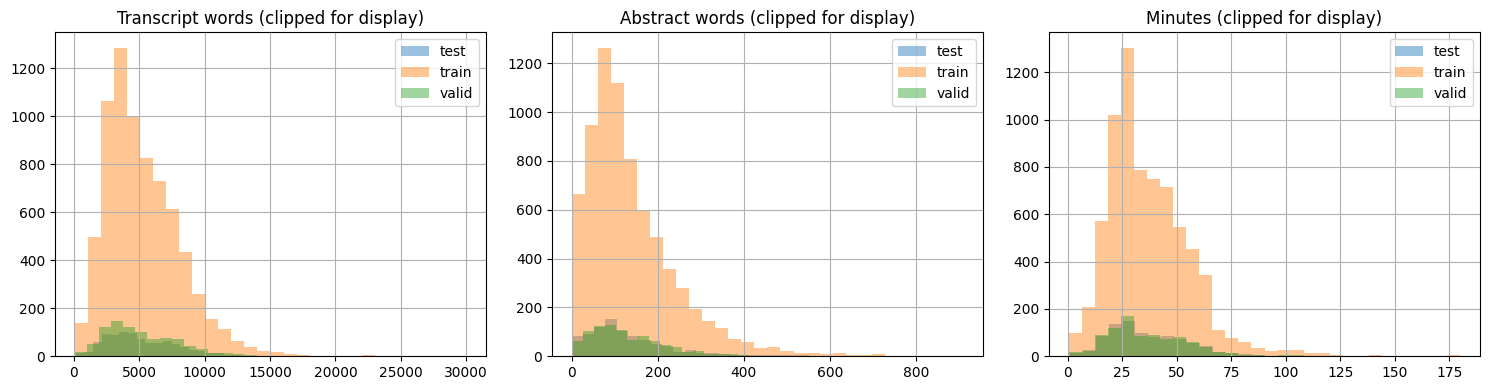

Cross-split shared DOI/title/author groups: {'doi': 0, 'title': 11, 'author': 398}
Cross-split rows requiring review: 1579
All cross-split title rows:


,field,normalized_value,split,source_index,doi
0,title,abusing p2p to hack 3 million cameras,train,7237,10.5446/49779 (DOI)
1,title,abusing p2p to hack 3 million cameras,test,456,10.5446/49740 (DOI)
2,title,automated firewall testing,train,345,10.5446/45171 (DOI)
3,title,automated firewall testing,valid,854,10.5446/44154 (DOI)
4,title,beyond the basics with elasticsearch,train,3509,10.5446/32798 (DOI)
5,title,beyond the basics with elasticsearch,valid,268,10.5446/20127 (DOI)
6,title,closing ceremonies,train,4383,10.5446/48419 (DOI)
7,title,closing ceremonies,test,855,10.5446/38988 (DOI)
8,title,"everything you always wanted to know about ""he...",train,4341,10.5446/42007 (DOI)
9,title,"everything you always wanted to know about ""he...",test,102,10.5446/45495 (DOI)


Cross-split group table (pandas may abbreviate long output):


,field,normalized_value,records,splits
0,author,"abate, pietro",2,"train, valid"
1,author,"abel, anders",2,"train, valid"
2,author,"adams, allan",12,"train, valid"
3,author,"adams, caitlin",2,"test, train"
4,author,"adams, till",2,"test, train"
...,...,...,...,...
404,title,mainframe surrogat chains,2,"test, valid"
405,title,micropython – python for microcontrollers,2,"test, train"
406,title,"old irish – morphosyntactic structures, part 3",2,"train, valid"
407,title,"old irish – morphosyntactic structures, part 4",2,"test, train"


Per-record cross-split ledger (filter shared_df for any group):


,field,normalized_value,split,source_index,doi
0,title,abusing p2p to hack 3 million cameras,train,7237,10.5446/49779 (DOI)
1,title,abusing p2p to hack 3 million cameras,test,456,10.5446/49740 (DOI)
2,title,automated firewall testing,train,345,10.5446/45171 (DOI)
3,title,automated firewall testing,valid,854,10.5446/44154 (DOI)
4,title,beyond the basics with elasticsearch,train,3509,10.5446/32798 (DOI)
...,...,...,...,...,...
1574,author,"zwiebach, barton",test,349,10.5446/42645 (DOI)
1575,author,"zwiebach, barton",test,353,10.5446/42630 (DOI)
1576,author,"zwiebach, barton",test,894,10.5446/42627 (DOI)
1577,author,"čermák, dan",train,1621,10.5446/54663 (DOI)


In [3]:
from collections import Counter
exclusion_counts = Counter(reason for reasons in manifest_df['exclusion_reasons'] for reason in reasons)
audit_flag_counts = Counter(flag for flags in manifest_df['audit_flags'] for flag in flags)
print('Transcript-structure exclusions:', dict(exclusion_counts))
print('DOI/source warnings:', dict(audit_flag_counts))
excluded_rows = manifest_df.loc[~manifest_df['usable'], ['split','source_index','doi','genre','exclusion_reasons']]
print('All structurally excluded source rows:', len(excluded_rows))
with pd.option_context('display.max_rows', len(excluded_rows) + 1):
    display(excluded_rows)
for field in ['transcript_words','abstract_words','segment_count','duration_minutes']:
    print(field)
    display(manifest_df.groupby('split')[field].describe(percentiles=[.1,.25,.5,.75,.9]))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for split, group in manifest_df.groupby('split'):
    group['transcript_words'].clip(upper=30000).hist(ax=axes[0], bins=30, alpha=.45, label=split)
    group['abstract_words'].clip(upper=1000).hist(ax=axes[1], bins=30, alpha=.45, label=split)
    group['duration_minutes'].dropna().clip(upper=180).hist(ax=axes[2], bins=30, alpha=.45, label=split)
for ax, title in zip(axes, ['Transcript words (clipped for display)','Abstract words (clipped for display)','Minutes (clipped for display)']):
    ax.set_title(title); ax.legend()
fig.tight_layout(); plt.show()
print('Cross-split shared DOI/title/author groups:', cohort['cross_split_shared_group_counts'])
shared_rows = []
for field in ('doi', 'title', 'author'):
    keys = manifest_df[field].fillna('').astype(str).map(lambda value: ' '.join(value.casefold().split()))
    for key, group in manifest_df.assign(group_key=keys).loc[keys.ne('')].groupby('group_key'):
        if group['split'].nunique() > 1:
            for row in group.itertuples(index=False):
                shared_rows.append({'field':field,'normalized_value':key,'split':row.split,
                                    'source_index':int(row.source_index),'doi':row.doi})
shared_df = pd.DataFrame(shared_rows, columns=['field','normalized_value','split','source_index','doi'])
print('Cross-split rows requiring review:',len(shared_df))
print('All cross-split title rows:')
display(shared_df.loc[shared_df['field'].eq('title')])
shared_group_table = (shared_df.groupby(['field','normalized_value'])
    .agg(records=('source_index','size'),
         splits=('split',lambda values: ', '.join(sorted(set(values)))))
    .reset_index())
print('Cross-split group table (pandas may abbreviate long output):')
display(shared_group_table)
print('Per-record cross-split ledger (filter shared_df for any group):')
display(shared_df)


In [4]:
details = detail_ns['scan_all_dataset_details'](cohort['usable'])
assert len(details) == cohort['usable_count']
assert {(row['split'], row['source_index']) for row in details} == {(row['split'], row['source_index']) for row in cohort['usable']}
detail_df = pd.DataFrame(details)
if len(detail_df):
    review_df = detail_df.reindex(columns=['split','source_index','doi','status','genre','source_url','license_label',
        'abstract_words','abstract_preview','transcript_words','transcript_matches_segments',
        'keyframe_count','keyframe_arrays_aligned','keyframe_intervals_ordered','video_url_present']).copy()
    review_df['reference_status'] = 'unverified_creator_abstract'
    review_df['media_status'] = 'not_decoded'
    review_df['short_abstract_under_30_words'] = pd.to_numeric(review_df['abstract_words'], errors='coerce').lt(30)
    print('Reference and media qualification status by split:')
    display(review_df.groupby(['split','reference_status','media_status'], dropna=False).size().rename('records').reset_index())
    display(review_df.groupby('split', dropna=False)[['short_abstract_under_30_words']].sum())
    display(review_df.loc[review_df['short_abstract_under_30_words']].head(30))
    print('Per-record reference/media review table (filter review_df by split/source_index):')
    display(review_df)
detail_lookup = {(row['split'], row['source_index']): row for row in details}
manifest_df['detail_status'] = [detail_lookup.get((row['split'], row['source_index']), {}).get('status', 'not_run_unusable_transcript')
                                for _, row in manifest_df.iterrows()]
print('Detailed scan statuses:', manifest_df['detail_status'].value_counts().to_dict())
print('Per-split detail coverage:')
display(pd.crosstab(manifest_df['split'], manifest_df['detail_status']))
complete = observed_counts == expected_counts and detail_df['status'].eq('ok').all()
coverage = {
    'dataset': cohort['dataset'], 'revision': cohort['revision'],
    'splits_read': cohort['splits_read'], 'test_content_accessed': True,
    'final_test_holdout_sealed': False, 'expected_counts': expected_counts,
    'observed_counts': observed_counts, 'source_count': cohort['source_count'],
    'text_usable_count': cohort['usable_count'], 'detail_status_counts': manifest_df['detail_status'].value_counts().to_dict(),
    'source_rows_accounted_for': len(manifest_df), 'structural_eda_complete': bool(complete),
    'reference_ground_truth_qualified': False, 'media_pixels_or_audio_read': False,
    'evaluation_status': 'not_frozen', 'decision': 'LIMIT: source/reference/media review and scoreable cohort pending'
}
display(detail_df.loc[detail_df['status'].ne('ok')].reindex(columns=['split','source_index','doi','status','error']).head(40))
print('Run coverage and claim boundary:')
display(pd.DataFrame([{'field':key,'value':value} for key,value in coverage.items()]))
print('Source audit ledger (filter manifest_df by split/source_index):')
display(manifest_df[['split','source_index','doi','genre','usable','exclusion_reasons','audit_flags','detail_status']])


Reference and media qualification status by split:


,split,reference_status,media_status,records
0,test,unverified_creator_abstract,not_decoded,899
1,train,unverified_creator_abstract,not_decoded,7199
2,valid,unverified_creator_abstract,not_decoded,904


,short_abstract_under_30_words
split,
test,91
train,612
valid,74


,split,source_index,doi,status,genre,source_url,license_label,abstract_words,abstract_preview,transcript_words,transcript_matches_segments,keyframe_count,keyframe_arrays_aligned,keyframe_intervals_ordered,video_url_present,reference_status,media_status,short_abstract_under_30_words
51,train,51,10.5446/49067 (DOI),ok,Lecture,https://av.tib.eu/media/49067,CC Attribution - NonCommercial - NoDerivatives...,10,"Introduction to the early Latin language, its ...",1950,True,12,True,True,True,unverified_creator_abstract,not_decoded,True
68,train,68,10.5446/40811 (DOI),ok,Conference/Talk,https://av.tib.eu/media/40811,CC Attribution 3.0 Unported:,11,WMS-V - Video Map Tiles for the 3rd or 4th Dim...,2274,True,20,True,True,True,unverified_creator_abstract,not_decoded,True
75,train,75,10.5446/18063 (DOI),ok,Conference/Talk,https://av.tib.eu/media/18063,CC Attribution 3.0 Unported:,13,Felix shows off some really interesting visual...,1603,True,19,True,True,True,unverified_creator_abstract,not_decoded,True
91,train,91,10.5446/48154 (DOI),ok,Lecture,https://av.tib.eu/media/48154,CC Attribution 3.0 Unported:,28,We will provide an overview of some of the mai...,6806,True,64,True,True,True,unverified_creator_abstract,not_decoded,True
102,train,102,10.5446/56646 (DOI),ok,Conference/Talk,https://av.tib.eu/media/56646,CC Attribution 3.0 Germany:,20,"Addon that uses Volto Slate plugin, to allow u...",1887,True,34,True,True,True,unverified_creator_abstract,not_decoded,True
125,train,125,10.5446/50997 (DOI),ok,Conference/Talk,https://av.tib.eu/media/50997,CC Attribution 3.0 Unported:,16,The NFDI4Microbiota Work Programme - Empowerin...,9356,True,85,True,True,True,unverified_creator_abstract,not_decoded,True
135,train,135,10.5446/49504 (DOI),ok,Lecture,https://av.tib.eu/media/49504,CC Attribution - NonCommercial - NoDerivatives...,22,Introduction to the clause structure of Gothic...,1873,True,22,True,True,True,unverified_creator_abstract,not_decoded,True
149,train,149,10.5446/48279 (DOI),ok,Conference/Talk,https://av.tib.eu/media/48279,CC Attribution 3.0 Unported:,10,The usual opening session and review of things...,1692,True,17,True,True,True,unverified_creator_abstract,not_decoded,True
158,train,158,10.5446/49753 (DOI),ok,Conference/Talk,https://av.tib.eu/media/49753,CC Attribution 3.0 Unported:,16,Question and Answer session for Christopher Wa...,6328,True,28,True,True,True,unverified_creator_abstract,not_decoded,True
168,train,168,10.5446/46961 (DOI),ok,Conference/Talk,https://av.tib.eu/media/46961,CC Attribution 2.0 Belgium:,28,The state of KDE (the Plasma desktop and appli...,2009,True,19,True,True,True,unverified_creator_abstract,not_decoded,True


Per-record reference/media review table (filter review_df by split/source_index):


,split,source_index,doi,status,genre,source_url,license_label,abstract_words,abstract_preview,transcript_words,transcript_matches_segments,keyframe_count,keyframe_arrays_aligned,keyframe_intervals_ordered,video_url_present,reference_status,media_status,short_abstract_under_30_words
0,train,0,10.5446/18349 (DOI),ok,Lecture,https://av.tib.eu/media/18349,CC Attribution 3.0 Unported:,45,Professor de Cooman takes the topic of rod and...,5722,True,73,True,True,True,unverified_creator_abstract,not_decoded,False
1,train,1,10.5446/47465 (DOI),ok,Conference/Talk,https://av.tib.eu/media/47465,CC Attribution 2.0 Belgium:,93,"In FOSDEM 2013, Open Robotics introduced an ov...",3623,True,35,True,True,True,unverified_creator_abstract,not_decoded,False
2,train,2,10.5446/43826 (DOI),ok,Conference/Talk,https://av.tib.eu/media/43826,CC Attribution 4.0 International:,33,How to build a pinball machine? We introduce y...,8962,True,44,True,True,True,unverified_creator_abstract,not_decoded,False
3,train,3,10.5446/42853 (DOI),ok,Conference/Talk,https://av.tib.eu/media/42853,CC Attribution 3.0 Germany:,151,Differential privacy is a mathematically rigor...,9336,True,102,True,True,True,unverified_creator_abstract,not_decoded,False
4,train,4,10.5446/19424 (DOI),ok,Lecture,https://av.tib.eu/media/19424,CC Attribution 3.0 Unported:,76,UCI Chem 51C Organic Chemistry (Spring 2012) L...,8787,True,79,True,True,True,unverified_creator_abstract,not_decoded,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8997,test,906,10.5446/42200 (DOI),ok,Conference/Talk,https://av.tib.eu/media/42200,CC Attribution 2.0 Belgium:,138,Following the progress of the Modularity initi...,4874,True,41,True,True,True,unverified_creator_abstract,not_decoded,False
8998,test,907,10.5446/19005 (DOI),ok,Lecture,https://av.tib.eu/media/19005,CC Attribution - ShareAlike 3.0 USA:,31,UCI Chem 1C is the third and final quarter of ...,7403,True,35,True,True,True,unverified_creator_abstract,not_decoded,False
8999,test,908,10.5446/18328 (DOI),ok,Lecture,https://av.tib.eu/media/18328,CC Attribution 3.0 Unported:,48,Professor de Cooman talks about the cold rolli...,7479,True,113,True,True,True,unverified_creator_abstract,not_decoded,False
9000,test,909,10.5446/31295 (DOI),ok,Conference/Talk,https://av.tib.eu/media/31295,CC Attribution - ShareAlike 3.0 Unported:,86,Are you ready to begin building applications w...,4717,True,51,True,True,True,unverified_creator_abstract,not_decoded,False


... (3 outputs left out)

Run coverage and claim boundary:


,field,value
0,dataset,gigant/tib
1,revision,e6ab9fd7c6acd164f3284b8c4b17eb9d94681eee
2,splits_read,"[train, valid, test]"
3,test_content_accessed,True
4,final_test_holdout_sealed,False
5,expected_counts,"{'train': 7282, 'valid': 910, 'test': 911}"
6,observed_counts,"{'train': 7282, 'valid': 910, 'test': 911}"
7,source_count,9103
8,text_usable_count,9002
9,detail_status_counts,"{'ok': 9002, 'not_run_unusable_transcript': 101}"


Source audit ledger (filter manifest_df by split/source_index):


,split,source_index,doi,genre,usable,exclusion_reasons,audit_flags,detail_status
0,train,0,10.5446/18349 (DOI),Lecture,True,[],[],ok
1,train,1,10.5446/47465 (DOI),Conference/Talk,True,[],[],ok
2,train,2,10.5446/43826 (DOI),Conference/Talk,True,[],[],ok
3,train,3,10.5446/42853 (DOI),Conference/Talk,True,[],[],ok
4,train,4,10.5446/19424 (DOI),Lecture,True,[],[],ok
...,...,...,...,...,...,...,...,...
9098,test,906,10.5446/42200 (DOI),Conference/Talk,True,[],[],ok
9099,test,907,10.5446/19005 (DOI),Lecture,True,[],[],ok
9100,test,908,10.5446/18328 (DOI),Lecture,True,[],[],ok
9101,test,909,10.5446/31295 (DOI),Conference/Talk,True,[],[],ok


## Trực quan EDA TIB và diễn giải kết quả

Chạy Runtime → Run all để xem bốn hình và phần diễn giải ngay trong notebook. Các ô hình dùng bảng trong bộ nhớ do các ô EDA phía trên tạo; sau khi Run all có thể chạy lại hai ô hình trên CPU mà không tải lại TIB. Hình và bảng thống kê chỉ xuất hiện trong notebook, không xuất file riêng. Đồ thị chỉ mô tả cấu trúc và metadata, không xác nhận abstract là ground truth.


Revision: e6ab9fd7c6acd164f3284b8c4b17eb9d94681eee
Source rows: 9103 | detail rows: 9002
Test inspected: True | reference GT qualified: False


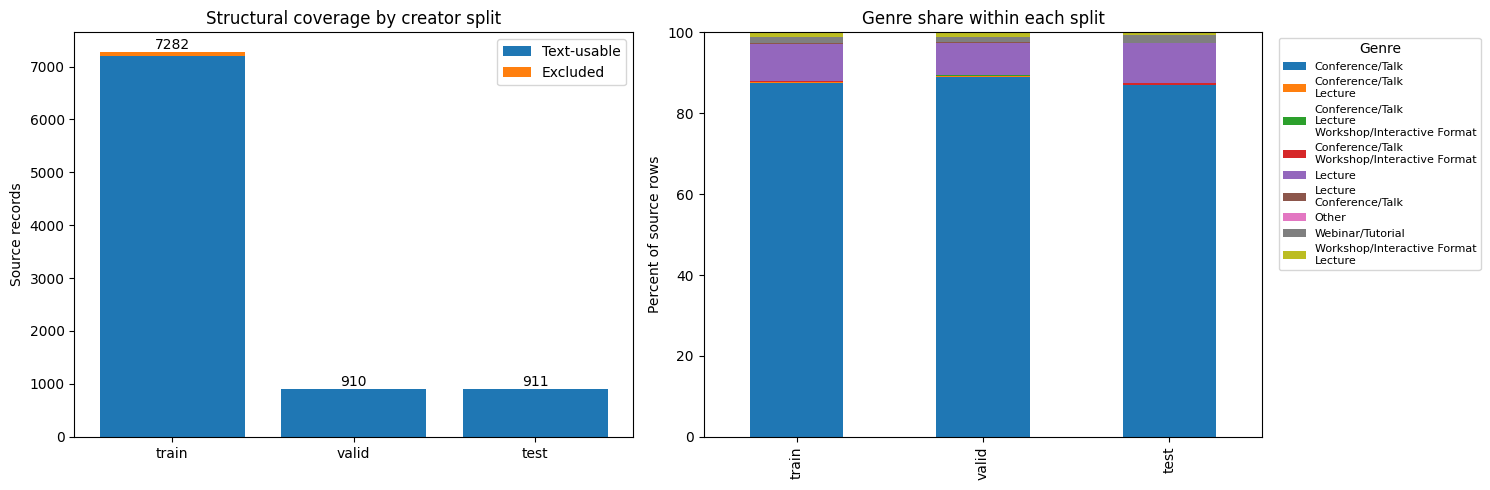

,text_usable,source_rows,excluded
split,,,
train,7199,7282,83
valid,904,910,6
test,899,911,12


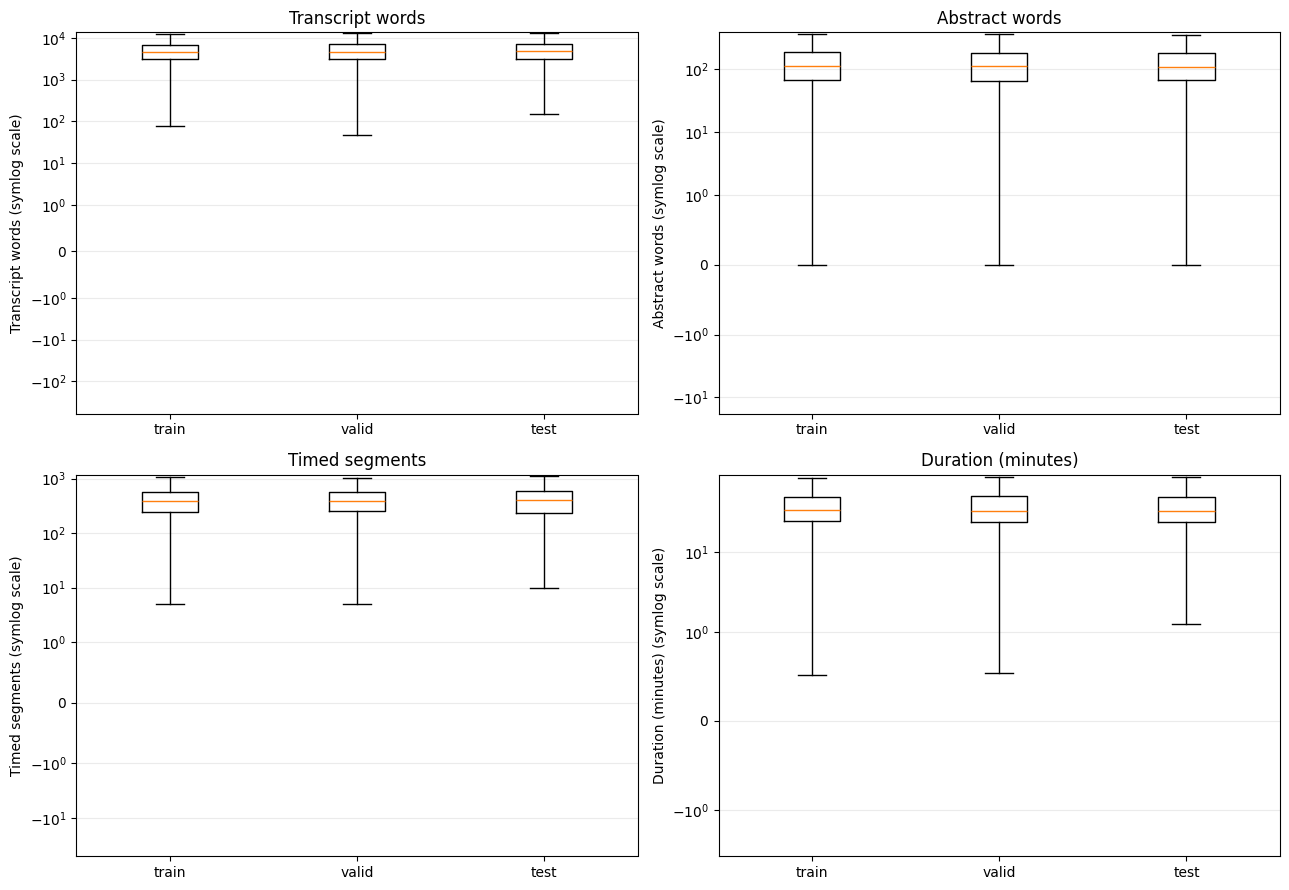

,split,field,observed,missing_or_invalid,p10,median,p90
0,train,transcript_words,7282,0,2193.800000,4702.000000,8961.900000
1,valid,transcript_words,910,0,2090.000000,4566.500000,9026.200000
2,test,transcript_words,911,0,2146.000000,4728.000000,9005.000000
3,train,abstract_words,7282,0,32.000000,110.000000,275.000000
4,valid,abstract_words,910,0,33.000000,110.000000,253.100000
5,test,abstract_words,911,0,29.000000,106.000000,269.000000
6,train,segment_count,7282,0,164.000000,381.000000,812.000000
7,valid,segment_count,910,0,155.000000,386.500000,803.200000
8,test,segment_count,911,0,164.000000,396.000000,857.000000
9,train,duration_minutes,7199,83,17.140267,32.905332,60.657866


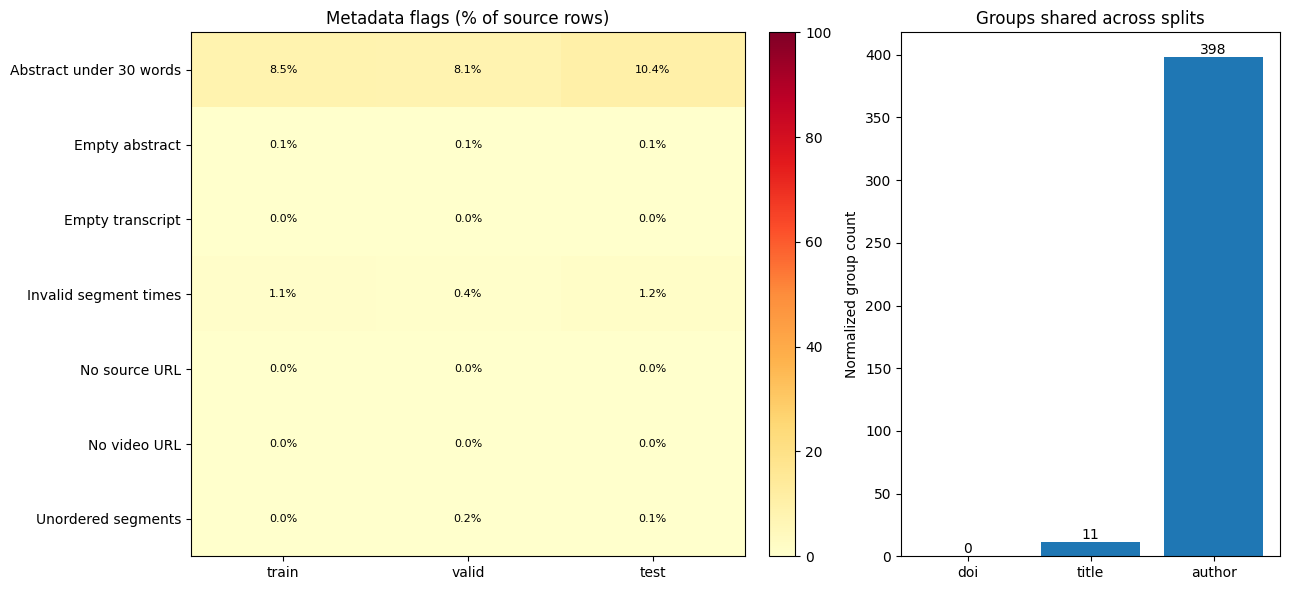

,flag,split,count,denominator,percent
0,Empty transcript,train,0,7282,0.000000
1,Empty transcript,valid,0,910,0.000000
2,Empty transcript,test,0,911,0.000000
3,Empty abstract,train,6,7282,0.082395
4,Empty abstract,valid,1,910,0.109890
5,Empty abstract,test,1,911,0.109769
6,Abstract under 30 words,train,621,7282,8.527877
7,Abstract under 30 words,valid,74,910,8.131868
8,Abstract under 30 words,test,95,911,10.428101
9,No source URL,train,0,7282,0.000000


Shared title/author is a review flag, not proof of duplication.


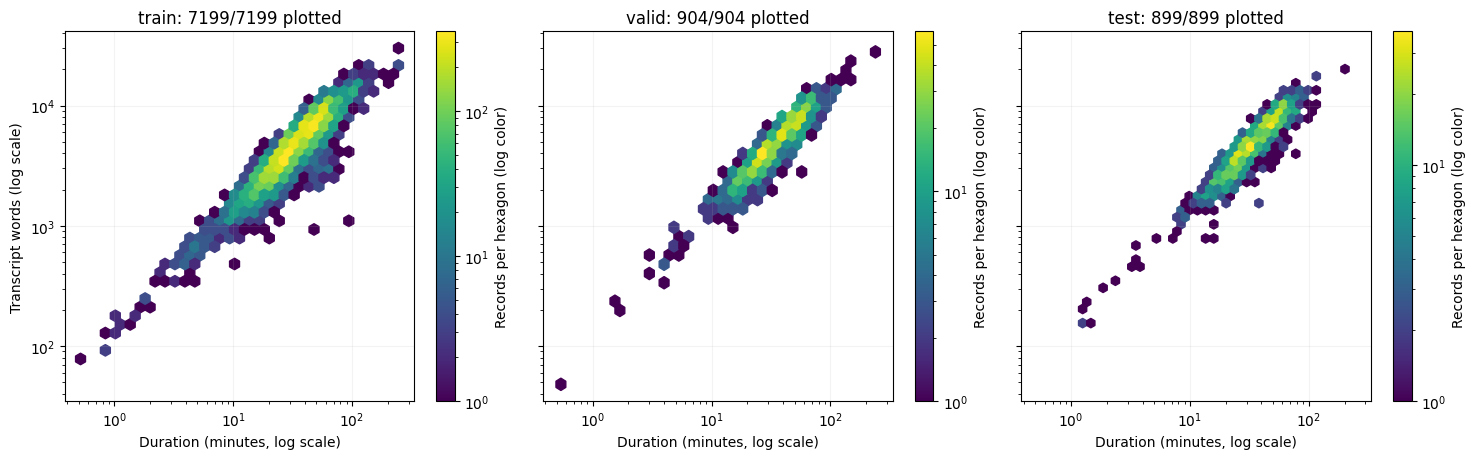

,split,detail_rows,plotted_positive_pairs
0,train,7199,7199
1,valid,904,904
2,test,899,899


Four figures and their underlying tables are shown above; no sidecar files were created.


In [5]:
# Use the in-memory EDA tables; Run all from the first cell.
cohort_v=cohort
coverage_v=coverage
manifest_v=manifest_df.copy()
details_v=detail_df.copy()
splits=['train','valid','test']
assert coverage_v['structural_eda_complete']
assert cohort_v['revision']==coverage_v['revision']
assert len(manifest_v)==coverage_v['source_count']
assert len(details_v)==coverage_v['text_usable_count']
assert set(zip(details_v['split'],details_v['source_index']))=={
    (row['split'],row['source_index']) for row in cohort_v['usable']}
assert details_v['status'].eq('ok').all()
def show_figure(fig):
    fig.tight_layout()
    plt.show()
    plt.close(fig)
print('Revision:',cohort_v['revision'])
print('Source rows:',len(manifest_v),'| detail rows:',len(details_v))
print('Test inspected:',coverage_v['test_content_accessed'],
      '| reference GT qualified:',coverage_v['reference_ground_truth_qualified'])

# Coverage and genre: denominators are all source rows, with no genre filter.
counts=manifest_v.groupby('split')['usable'].agg(['sum','count']).reindex(splits).astype(int)
counts['excluded']=counts['count']-counts['sum']
genre=manifest_v['genre'].fillna('').astype(str).replace('', '(missing)')
top=genre.value_counts().head(8).index
genre_group=genre.where(genre.isin(top),'Other')
genre_table=pd.crosstab(manifest_v['split'],genre_group).reindex(splits,fill_value=0)
genre_pct=genre_table.div(counts['count'],axis=0).mul(100)
fig,axes=plt.subplots(1,2,figsize=(15,5))
axes[0].bar(splits,counts['sum'],label='Text-usable')
axes[0].bar(splits,counts['excluded'],bottom=counts['sum'],label='Excluded')
for i,row in enumerate(counts.itertuples()):
    axes[0].text(i,row.count,str(row.count),ha='center',va='bottom')
axes[0].set_title('Structural coverage by creator split')
axes[0].set_ylabel('Source records')
axes[0].legend()
genre_pct.plot.bar(stacked=True,ax=axes[1],legend=False)
axes[1].set_title('Genre share within each split')
axes[1].set_ylabel('Percent of source rows')
axes[1].set_xlabel('')
axes[1].set_ylim(0,100)
axes[1].legend(title='Genre',bbox_to_anchor=(1.02,1),loc='upper left',fontsize=8)
show_figure(fig)
display(counts.rename(columns={'sum':'text_usable','count':'source_rows'}))

# Full-value quantiles accompany boxplots; only outlier markers are hidden.
metrics=[('transcript_words','Transcript words'),('abstract_words','Abstract words'),
         ('segment_count','Timed segments'),('duration_minutes','Duration (minutes)')]
fig,axes=plt.subplots(2,2,figsize=(13,9))
quantile_rows=[]
for ax,(field,label) in zip(axes.flat,metrics):
    numeric=pd.to_numeric(manifest_v[field],errors='coerce')
    groups=[]
    for split in splits:
        values=numeric.loc[manifest_v['split'].eq(split)].dropna()
        values=values.loc[values.ge(0)]
        groups.append(values)
        quantile_rows.append({'split':split,'field':field,'observed':len(values),
            'missing_or_invalid':int(manifest_v['split'].eq(split).sum()-len(values)),
            'p10':values.quantile(.10),'median':values.median(),'p90':values.quantile(.90)})
    ax.boxplot(groups,showfliers=False)
    ax.set_xticks(range(1,4),splits)
    ax.set_yscale('symlog',linthresh=1)
    ax.set_title(label)
    ax.set_ylabel(label+' (symlog scale)')
    ax.grid(axis='y',alpha=.25)
show_figure(fig)
quantiles_v=pd.DataFrame(quantile_rows)
display(quantiles_v)

# Rates use all source rows; abstract length is not a reference-quality label.
flags={
 'Empty transcript':pd.to_numeric(manifest_v['transcript_words'],errors='coerce').fillna(0).eq(0),
 'Empty abstract':pd.to_numeric(manifest_v['abstract_words'],errors='coerce').fillna(0).eq(0),
 'Abstract under 30 words':pd.to_numeric(manifest_v['abstract_words'],errors='coerce').fillna(0).lt(30),
 'No source URL':~manifest_v['source_url_present'].astype(bool),
 'No video URL':~manifest_v['video_url_present'].astype(bool),
 'Invalid segment times':~manifest_v['segments_valid_times'].astype(bool),
 'Unordered segments':manifest_v['exclusion_reasons'].apply(lambda reasons: 'unordered_segments' in reasons)}
flag_rows=[]
for name,mask in flags.items():
    for split in splits:
        selected=mask.loc[manifest_v['split'].eq(split)]
        flag_rows.append({'flag':name,'split':split,'count':int(selected.sum()),
                          'denominator':len(selected),'percent':100*selected.mean()})
flag_table=pd.DataFrame(flag_rows)
rate_matrix=flag_table.pivot(index='flag',columns='split',values='percent')[splits]
shared=cohort_v['cross_split_shared_group_counts']
fig,axes=plt.subplots(1,2,figsize=(13,6),gridspec_kw={'width_ratios':[1.6,1]})
image=axes[0].imshow(rate_matrix.to_numpy(),aspect='auto',cmap='YlOrRd',vmin=0,vmax=100)
axes[0].set_yticks(range(len(rate_matrix)),rate_matrix.index)
axes[0].set_xticks(range(3),splits)
axes[0].set_title('Metadata flags (% of source rows)')
for i in range(len(rate_matrix)):
    for j in range(3):
        value=rate_matrix.iloc[i,j]
        axes[0].text(j,i,f'{value:.1f}%',ha='center',va='center',
                     color='white' if value>55 else 'black',fontsize=8)
fig.colorbar(image,ax=axes[0],fraction=.046,pad=.04)
fields=['doi','title','author']
values=[int(shared.get(field,0)) for field in fields]
axes[1].bar(fields,values)
for i,value in enumerate(values):
    axes[1].text(i,value,str(value),ha='center',va='bottom')
axes[1].set_title('Groups shared across splits')
axes[1].set_ylabel('Normalized group count')
show_figure(fig)
display(flag_table)
print('Shared title/author is a review flag, not proof of duplication.')

# Every positive duration/word pair is plotted; the color is density within each split.
fig,axes=plt.subplots(1,3,figsize=(15,4.7),sharex=True,sharey=True)
relationship=[]
for ax,split in zip(axes,splits):
    subset=details_v.loc[details_v['split'].eq(split)]
    duration=pd.to_numeric(subset['duration_minutes'],errors='coerce')
    words=pd.to_numeric(subset['transcript_words'],errors='coerce')
    valid=duration.gt(0)&words.gt(0)
    relationship.append({'split':split,'detail_rows':len(subset),
                         'plotted_positive_pairs':int(valid.sum())})
    if valid.any():
        density=ax.hexbin(duration.loc[valid],words.loc[valid],gridsize=32,mincnt=1,
                          bins='log',xscale='log',yscale='log',cmap='viridis')
        fig.colorbar(density,ax=ax,label='Records per hexagon (log color)')
    ax.set_title(f'{split}: {int(valid.sum())}/{len(subset)} plotted')
    ax.set_xlabel('Duration (minutes, log scale)')
    ax.grid(alpha=.15)
axes[0].set_ylabel('Transcript words (log scale)')
show_figure(fig)
relationship_v=pd.DataFrame(relationship)
display(relationship_v)
print('Four figures and their underlying tables are shown above; no sidecar files were created.')


### Nhận xét định lượng và quyết định EDA

Các nhận xét dưới đây được tính lại từ đúng các bảng đã vẽ; chúng không tự động xác nhận chất lượng reference.


In [6]:
from collections import Counter
from IPython.display import Markdown

exclusions=Counter()
for row in cohort_v['manifest']:
    for reason in row['exclusion_reasons']:
        exclusions[(row['split'],reason)]+=1
exclusion_table=pd.DataFrame(
    [{'split':split,'reason':reason,'count':count} for (split,reason),count in sorted(exclusions.items())],
    columns=['split','reason','count'])
display(Markdown('### Diễn giải dựa trên bốn đồ thị'))
display(exclusion_table)
source_total=int(counts['count'].sum())
usable_total=int(counts['sum'].sum())
excluded_total=int(counts['excluded'].sum())
coverage_note=', '.join(
    f"{split}: {int(counts.loc[split,'sum']):,}/{int(counts.loc[split,'count']):,} text-usable"
    for split in splits)
dominant_genres=', '.join(
    f"{split}: {genre_table.loc[split].idxmax()} "
    f"({int(genre_table.loc[split].max()):,}/{int(counts.loc[split,'count']):,})"
    for split in splits)
median_words=', '.join(
    f"{split}: {quantiles_v.loc[(quantiles_v['split']==split)&(quantiles_v['field']=='transcript_words'),'median'].iloc[0]:,.0f}"
    for split in splits)
median_minutes=', '.join(
    f"{split}: {quantiles_v.loc[(quantiles_v['split']==split)&(quantiles_v['field']=='duration_minutes'),'median'].iloc[0]:.1f}"
    for split in splits)
abstract_short=flag_table.loc[flag_table['flag'].eq('Abstract under 30 words')]
short_note=', '.join(
    f"{row.split}: {int(row.count):,}/{int(row.denominator):,} ({row.percent:.1f}%)"
    for row in abstract_short.itertuples())
shared_note=', '.join(f"{field}: {int(shared.get(field,0)):,}" for field in ['doi','title','author'])
plotted_note=', '.join(
    f"{row.split}: {int(row.plotted_positive_pairs):,}/{int(row.detail_rows):,}"
    for row in relationship_v.itertuples())
match_count=int(details_v['transcript_matches_segments'].astype(str).str.lower().eq('true').sum())
findings=[
    {'figure':'01 coverage/genre','observation':f"{usable_total:,}/{source_total:,} structurally text-usable; "
     f"{excluded_total:,} excluded. {coverage_note}. Dominant genres: {dominant_genres}.",
     'interpretation':'All source rows are counted; genre is a stratum, not an exclusion rule.'},
    {'figure':'02 length/duration','observation':f"Median transcript words: {median_words}. "
     f"Median duration in minutes: {median_minutes}.",
     'interpretation':'Compare p10/median/p90 in the displayed table; boxplots hide outlier markers but use all observed values.'},
    {'figure':'03 metadata flags/groups','observation':f"Abstracts under 30 words: {short_note}. "
     f"Groups shared across splits: {shared_note}.",
     'interpretation':'Short abstracts need review; title/author matches are group-review flags, not proven duplicates.'},
    {'figure':'04 duration/transcript','observation':f"Positive pairs plotted: {plotted_note}. "
     f"Transcript/segment token match in detailed rows: {match_count:,}/{len(details_v):,}.",
     'interpretation':'Density describes the source corpus; it does not measure ASR accuracy or summary quality.'},
]
display(pd.DataFrame(findings))
decision=(
    f"**Structural EDA:** {source_total:,} source rows accounted for; "
    f"{usable_total:,} text-usable and {excluded_total:,} structurally excluded. "
    f"Per-split exclusion reasons are shown above. "
    "**Decision: LIMIT**: structural evidence alone; run the reference-screen section and declare the scoring claim. "
    "Source groups and decoded media need separate review for claims that require them. "
    "The notebook read creator test content, so that split is no longer unseen. "
    "No model comparison or factuality claim follows from these graphs."
)
display(Markdown('### EDA decision and claim boundary'))
display(Markdown(decision))
run_summary={
    'dataset':cohort_v['dataset'], 'revision':cohort_v['revision'],
    'source_rows':source_total, 'text_usable_rows':usable_total,
    'structurally_excluded_rows':excluded_total,
    'test_content_accessed':coverage_v['test_content_accessed'],
    'reference_ground_truth_qualified':coverage_v['reference_ground_truth_qualified'],
    'media_pixels_or_audio_read':coverage_v['media_pixels_or_audio_read'],
    'evaluation_status':coverage_v['evaluation_status'],
    'decision':'LIMIT',
}
display(pd.DataFrame([{'field':key,'value':value} for key,value in run_summary.items()]))


### Diễn giải dựa trên bốn đồ thị

,split,reason,count
0,test,invalid_segment_times,11
1,test,unordered_segments,1
2,train,invalid_segment_times,83
3,valid,invalid_segment_times,4
4,valid,unordered_segments,2


,figure,observation,interpretation
0,01 coverage/genre,"9,002/9,103 structurally text-usable; 101 excl...",All source rows are counted; genre is a stratu...
1,02 length/duration,"Median transcript words: train: 4,702, valid: ...",Compare p10/median/p90 in the displayed table;...
2,03 metadata flags/groups,"Abstracts under 30 words: train: 621/7,282 (8....",Short abstracts need review; title/author matc...
3,04 duration/transcript,"Positive pairs plotted: train: 7,199/7,199, va...",Density describes the source corpus; it does n...


### EDA decision and claim boundary

**Structural EDA:** 9,103 source rows accounted for; 9,002 text-usable and 101 structurally excluded. Per-split exclusion reasons are shown above. **Decision: LIMIT**: structural evidence alone; run the reference-screen section and declare the scoring claim. Source groups and decoded media need separate review for claims that require them. The notebook read creator test content, so that split is no longer unseen. No model comparison or factuality claim follows from these graphs.

,field,value
0,dataset,gigant/tib
1,revision,e6ab9fd7c6acd164f3284b8c4b17eb9d94681eee
2,source_rows,9103
3,text_usable_rows,9002
4,structurally_excluded_rows,101
5,test_content_accessed,True
6,reference_ground_truth_qualified,False
7,media_pixels_or_audio_read,False
8,evaluation_status,not_frozen
9,decision,LIMIT


### Nhận xét khoa học dữ liệu từ lần chạy đã kiểm tra

**Phạm vi.** Các số dưới đây là kết quả của lần chạy đã kiểm tra trước khi chuyển sang notebook chỉ hiển thị output; sau khi Run all phiên bản mới, cần đối chiếu lại. Nhận xét này dựa trên bốn hình và các bảng output của lần chạy pinned `gigant/tib@e6ab9fd7c6acd164f3284b8c4b17eb9d94681eee`. Đơn vị đếm là bản ghi creator, trừ khi ghi rõ là nhóm metadata. Các tỷ lệ theo split bên dưới dùng **toàn bộ bản ghi nguồn**; tỷ lệ abstract ngắn dùng riêng tập **text-usable**.

| Split | Nguồn | Text-usable | Bị loại cấu trúc | Tỷ lệ text-usable |
|:--|--:|--:|--:|--:|
| train | 7.282 | 7.199 | 83 | 98,86% |
| valid | 910 | 904 | 6 | 99,34% |
| test | 911 | 899 | 12 | 98,68% |
| **Tổng** | **9.103** | **9.002** | **101** | **98,89%** |

**Hình 01 — độ phủ và miền dữ liệu.** Việc quét bao phủ cả ba split và 9.002 bản ghi có transcript/segment đủ điều kiện **về cấu trúc**. Trong 101 bản ghi bị loại, 98 có thời gian segment không hợp lệ và 3 có thứ tự segment sai. Đây là lỗi cấu trúc đầu vào, chưa phải lỗi chất lượng bản tóm tắt. Genre `Conference/Talk` chiếm 6.364/7.282 train (87,4%), 810/910 valid (89,0%) và 792/911 test (86,9%); nhãn chính xác `Lecture` chỉ chiếm lần lượt 665 (9,1%), 71 (7,8%) và 91 (10,0%). Vì vậy, kết luận trên toàn TIB sẽ chủ yếu mô tả **conference talks**; cần xác nhận từng nội dung có thuộc miền bài giảng giáo dục trước khi gọi đây là benchmark lecture summarization. Genre chỉ là metadata, không đủ để tự động kết luận chất lượng hoặc loại mẫu.

**Hình 02 — độ dài và đuôi phân phối.** Trung vị transcript là 4.702 / 4.566,5 / 4.728 từ (train/valid/test); p90 khoảng 8.962 / 9.026 / 9.005 từ. Trung vị thời lượng là 32,9 / 32,8 / 32,7 phút; p90 đều khoảng 61 phút. Trung vị abstract là 110 / 110 / 106 từ. Các trung vị và p90 gần nhau cho thấy độ dài tổng quát tương đối tương tự giữa split, **không chứng minh** cùng phân phối nội dung hay độc lập nguồn. Đuôi dài (transcript tối đa 30.044 từ; thời lượng tối đa khoảng 246 phút ở train) tạo rủi ro cắt ngắn đầu vào: phải đo tỷ lệ token được giữ và kiểm soát ngân sách token trước khi so S1/S3. Boxplot đã ẩn dấu outlier để dễ đọc, nhưng bảng quantile và thống kê cực trị vẫn bao gồm chúng. Thời lượng có 906 valid và 900 test quan sát được, nhiều hơn 904/899 bản ghi text-usable vì một số bản ghi có thời gian hợp lệ nhưng segment sai thứ tự; không được dùng hai mẫu số này lẫn nhau.

**Hình 03 — reference và nguy cơ rò rỉ.** Trong tập text-usable, abstract dưới 30 từ có 612/7.199 train (8,50%), 74/904 valid (8,19%) và 91/899 test (10,12%). Độ ngắn là **cờ để đọc lại**, không phải bằng chứng abstract sai hoặc không dùng được. Tám abstract rỗng tính trên toàn nguồn (6/1/1 theo split). Metadata đã chuẩn hóa có 0 nhóm DOI, 11 nhóm title và 398 nhóm author xuất hiện qua nhiều split. Title/author chung không tự chứng minh trùng bài, nhưng đủ để kiểm tra cùng talk, chuỗi bài giảng và nguồn trước khi chia cohort an toàn. Không thể kết luận “không rò rỉ” chỉ từ 0 DOI trùng. **Lần chạy lại hình 03:** heatmap nay đếm riêng `unordered_segments`: train 0, valid 2, test 1; cờ thời gian không hợp lệ là train 83, valid 4, test 11. Hai cờ là hai loại loại trừ khác nhau, tổng lần lượt 3 và 98 bản ghi; chúng khớp với bảng `exclusion_table`.

**Hình 04 — quan hệ độ dài.** Toàn bộ 9.002 bản ghi chi tiết có cặp duration/transcript dương và được đưa vào hexbin. Đồ thị mô tả độ dài nguồn và mật độ quan sát, **không đo** độ chính xác ASR, mức thông tin được abstract bao phủ, tính đúng sự thật, hay chất lượng tóm tắt. Việc transcript khớp với phép ghép segment theo tokenizer cũng chỉ là phép kiểm tra nhất quán nội bộ.

**Kết luận sử dụng.** **KEEP** cho mô tả cấu trúc và phân tầng nguồn; **LIMIT/HOLD** cho đánh giá RQ2 chính thức. Trước khi chốt cohort cần: (1) đọc mẫu abstract theo từng nhóm độ dài/genre và xác minh nguồn gốc, mức phù hợp với mục tiêu tóm tắt; (2) xét các nhóm title/author cùng nguồn hoặc series để thiết kế split an toàn; (3) kiểm tra phân bổ nội dung và ngân sách token, nhất là đuôi dài. Bảng trạng thái `coverage` ghi `reference_ground_truth_qualified=false`, chưa giải mã media, và chưa freeze cohort. Lần EDA này đã đọc `test`, nên creator `test` không còn là holdout chưa xem. Hiện chưa có kết quả mô hình và không được diễn giải ROUGE như factuality.


### Quyết định sau khi chạy

Xem trực tiếp `manifest_df`, `shared_df`, `review_df` và bảng `coverage` ở trên. Mọi dòng nguồn phải được kiểm kê, mọi dòng text-usable phải có trạng thái chi tiết; các lỗi vẫn giữ trong ledger. Phần reference screen ở cuối notebook sàng lọc tự động mọi bản ghi và chọn mẫu duyệt đa dạng. Với ROUGE agreement, khai báo reference có nhiễu; không bắt buộc xác nhận thủ công từng abstract. Xét nhóm nguồn nếu có training/tuning, và kiểm tra media nếu benchmark dùng audio/video. Nếu muốn một kết luận trên holdout chưa xem, cần nguồn độc lập mới vì EDA này đã đọc cả `test`. **Sau khi Run all, lưu notebook kèm output để giữ bảng kiểm kê, bốn biểu đồ và phần diễn giải trong cùng một tệp. Chưa có kết quả mô hình hoặc reference ground truth đã xác nhận.**

**Lưu ý về bảng dài:** Pandas có thể rút gọn phần hiển thị của `manifest_df`, `shared_df` và `review_df`; dữ liệu đầy đủ ở các biến đó trong phiên Colab để lọc theo `(split, source_index)`. Notebook không nhúng toàn bộ 9.103 dòng vào output đã lưu. Vì không có file phụ, muốn tra cứu từng dòng sau khi đóng phiên cần chạy lại notebook trên revision đã ghim.


## Sàng lọc reference và nội dung cho benchmark dùng abstract TIB

Phần này dùng **toàn bộ transcript** trong lần quét detail ở đầu notebook, không dùng `transcript_example`. Chạy lại **Run all** sau khi cập nhật. Mọi kết quả, hình, ID và lý do nằm trong notebook; không xuất receipt riêng.

**Chính sách:** loại abstract rỗng và mọi thành viên của nhóm abstract trùng sau casefold + gộp khoảng trắng (chính sách bảo thủ để tránh template dùng chung). Abstract ngắn, cụm từ giới thiệu khóa học/sự kiện, transcript trùng và mức khớp từ thấp chỉ là cờ duyệt. Không tự suy ra các bài trùng video từ tác giả/title chung.

**Độ phủ từ vựng:** số từ nội dung khác nhau của abstract tìm thấy ở bất kỳ chỗ nào trong transcript / số từ nội dung khác nhau của abstract. Bỏ stopword Anh/Đức đơn giản, không stemming, không đo ngữ nghĩa/factuality. Ngưỡng 0,25 chỉ để ưu tiên duyệt; không phải ngưỡng chất lượng đã hiệu chuẩn. Đoạn trích khớp từ cao giúp đọc đối chiếu, không chứng minh phát biểu được nguồn xác nhận. ASR sai, diễn đạt khác và ngôn ngữ khác có thể làm độ phủ thấp.
**Template gần trùng:** gắn cờ nếu ít nhất ba abstract dài từ 40 từ dùng chung 30 từ đầu đã chuẩn hóa; khác biệt ở phần sau vẫn được giữ. Đây là heuristic để đọc lại, không phải bằng chứng reference sai.


In [7]:
# Reuse functions embedded in DETAIL_SOURCE: no extra downloads or model calls.
LOW_LEXICAL_COVERAGE = 0.25
required = {'normalized_abstract_sha256', 'normalized_transcript_sha256',
            'reference_token_coverage', 'matched_source_excerpts', 'full_transcript_screened'}
assert required.issubset(detail_df.columns), 'Run all again: the saved detail table predates reference screening.'
assert coverage['structural_eda_complete'], 'Resolve structural/detail coverage errors first.'
reference_rows = detail_ns['annotate_reference_pool'](details, LOW_LEXICAL_COVERAGE)
reference_df = pd.DataFrame(reference_rows)
assert len(reference_df) == cohort['usable_count']
pool_df = reference_df.loc[reference_df['broad_pool_candidate']].copy()
reference_flag_counts = Counter(flag for flags in reference_df['reference_review_flags'] for flag in flags)
reference_exclusion_counts = Counter(reason for reasons in reference_df['reference_exclusion_reasons'] for reason in reasons)
print('Exclusions (counts may overlap):', dict(reference_exclusion_counts))
print('Review flags (counts may overlap):', dict(reference_flag_counts))
print('Broad candidate pool:', len(pool_df), '| all genres/splits, no benchmark size cap')
display(pd.crosstab(reference_df['split'], reference_df['screen_action']))
display(reference_df[['split','source_index','doi','genre','subject','abstract_words',
    'reference_token_coverage','abstract_group_size','transcript_group_size',
    'screen_action','reference_exclusion_reasons','reference_review_flags']])
# Hash groups identify reused normalized text, not semantic duplicates.
duplicate_reference_df = reference_df.loc[reference_df['abstract_group_size'].gt(1)]
display(duplicate_reference_df[['split','source_index','doi','normalized_abstract_sha256',
    'abstract_group_size','abstract_preview']])
print('Every excluded ID and reason:')
with pd.option_context('display.max_rows', None, 'display.max_colwidth', 120):
    display(reference_df.loc[~reference_df['broad_pool_candidate'],
        ['split','source_index','doi','reference_exclusion_reasons']])

Exclusions (counts may overlap): {'reused_abstract': 225, 'empty_abstract': 8}
Review flags (counts may overlap): {'course_scope_cue': 117, 'shared_30_word_prefix_template_cue': 121, 'short_abstract': 777, 'event_scope_cue': 22, 'low_lexical_coverage': 115}
Broad candidate pool: 8769 | all genres/splits, no benchmark size cap


screen_action,exclude,keep_candidate,review
split,,,
test,20,774,105
train,196,6296,707
valid,17,799,88


,split,source_index,doi,genre,subject,abstract_words,reference_token_coverage,abstract_group_size,transcript_group_size,screen_action,reference_exclusion_reasons,reference_review_flags
0,train,0,10.5446/18349 (DOI),Lecture,Engineering,45,0.346154,1,1,keep_candidate,[],[]
1,train,1,10.5446/47465 (DOI),Conference/Talk,Computer Science,93,0.418182,1,1,keep_candidate,[],[]
2,train,2,10.5446/43826 (DOI),Conference/Talk,Computer Science,33,0.800000,1,1,keep_candidate,[],[]
3,train,3,10.5446/42853 (DOI),Conference/Talk,Computer Science,151,0.705128,1,1,keep_candidate,[],[]
4,train,4,10.5446/19424 (DOI),Lecture,Chemistry,76,0.452381,1,1,keep_candidate,[],[]
...,...,...,...,...,...,...,...,...,...,...,...,...
8997,test,906,10.5446/42200 (DOI),Conference/Talk,Computer Science,138,0.553846,1,1,keep_candidate,[],[]
8998,test,907,10.5446/19005 (DOI),Lecture,Chemistry,31,0.409091,19,1,exclude,[reused_abstract],[]
8999,test,908,10.5446/18328 (DOI),Lecture,Engineering,48,0.592593,1,1,keep_candidate,[],[]
9000,test,909,10.5446/31295 (DOI),Conference/Talk,Computer Science,86,0.666667,1,1,keep_candidate,[],[]


,split,source_index,doi,normalized_abstract_sha256,abstract_group_size,abstract_preview
16,train,16,10.5446/18901 (DOI),1824edc6ba7022921c71ea4d3740612d7bc135d5aec073...,18,This course provides an introduction to quantu...
123,train,123,10.5446/19002 (DOI),610a31894503b8fa7c86f99496d2ce1a2a3fa3f476c2bd...,19,UCI Chem 1C is the third and final quarter of ...
148,train,148,10.5446/18982 (DOI),eb8e7ca445648f3858dedc3ceedded57e6816bfe86e723...,8,UCI Chem 1A is the first quarter of General Ch...
231,train,234,10.5446/19429 (DOI),49a92c4f52b9f00075957949eb596ecdb624513a5e2190...,21,UCI Chem 1B is the second quarter of General C...
233,train,236,10.5446/19492 (DOI),4c62b001e9a96b00a9e922e9bb91f7547bd8dcf71502b9...,18,This is the second quarter of the organic chem...
...,...,...,...,...,...,...
8933,test,840,10.5446/18934 (DOI),95ec9c56ff9f880685983bbaf83e14f2b64e294a72f6e6...,17,Principles of quantum mechanics with applicati...
8962,test,870,10.5446/19467 (DOI),49a92c4f52b9f00075957949eb596ecdb624513a5e2190...,21,UCI Chem 1B is the second quarter of General C...
8988,test,897,10.5446/18877 (DOI),19b1f6b913e4852a180ffa657643e539c6d41553473514...,10,Introduction to the basic principles of chemic...
8995,test,904,10.5446/18887 (DOI),1824edc6ba7022921c71ea4d3740612d7bc135d5aec073...,18,This course provides an introduction to quantu...


Every excluded ID and reason:


,split,source_index,doi,reference_exclusion_reasons
16,train,16,10.5446/18901 (DOI),[reused_abstract]
123,train,123,10.5446/19002 (DOI),[reused_abstract]
148,train,148,10.5446/18982 (DOI),[reused_abstract]
231,train,234,10.5446/19429 (DOI),[reused_abstract]
233,train,236,10.5446/19492 (DOI),[reused_abstract]
244,train,247,10.5446/21612 (DOI),[reused_abstract]
259,train,263,10.5446/19363 (DOI),[reused_abstract]
266,train,270,10.5446/19390 (DOI),[reused_abstract]
273,train,277,10.5446/18985 (DOI),[reused_abstract]
293,train,297,10.5446/19462 (DOI),[reused_abstract]


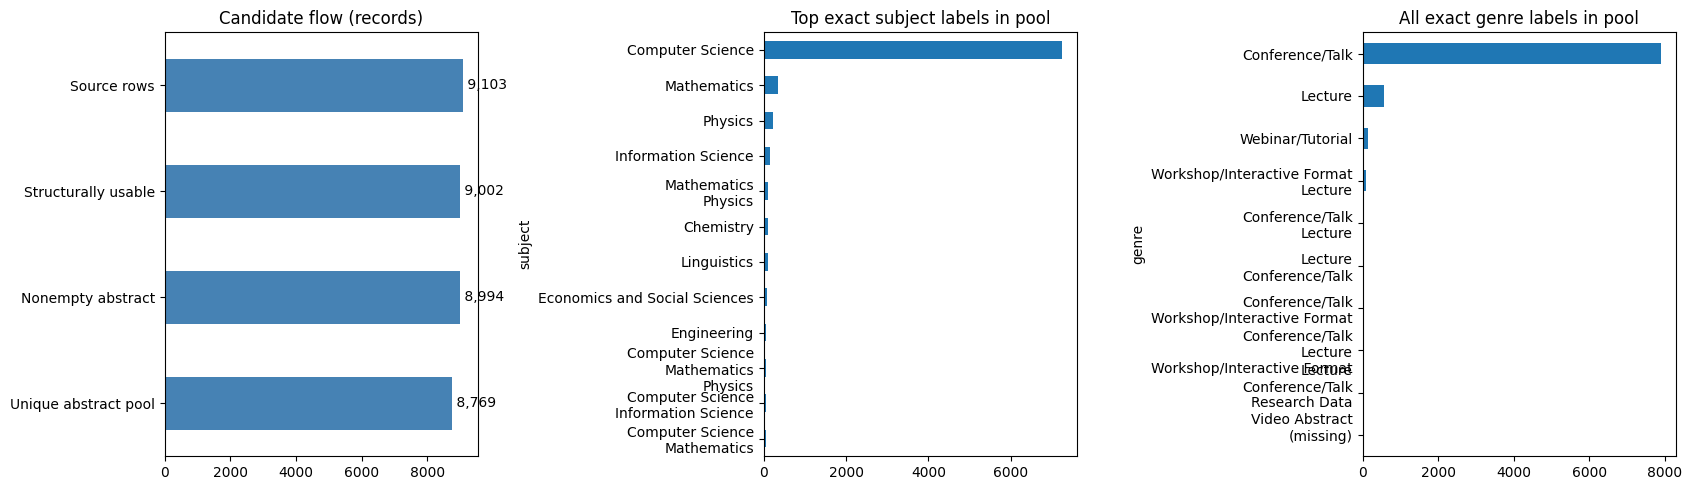

,records,percent
subject,,
Computer Science,7249,82.666211
Mathematics,357,4.071160
Physics,230,2.622876
Information Science,147,1.676360
Mathematics\nPhysics,114,1.300034
Chemistry,109,1.243015
Linguistics,101,1.151785
Economics and Social Sciences,75,0.855286
Engineering,59,0.672825


,records
genre,
Conference/Talk,7897
Lecture,570
Webinar/Tutorial,135
Workshop/Interactive Format\nLecture,91
Conference/Talk\nLecture,28
Lecture\nConference/Talk,25
Conference/Talk\nWorkshop/Interactive Format,17
Conference/Talk\nLecture\nWorkshop/Interactive Format,4
Lecture\nConference/Talk\nResearch Data\nVideo Abstract,1


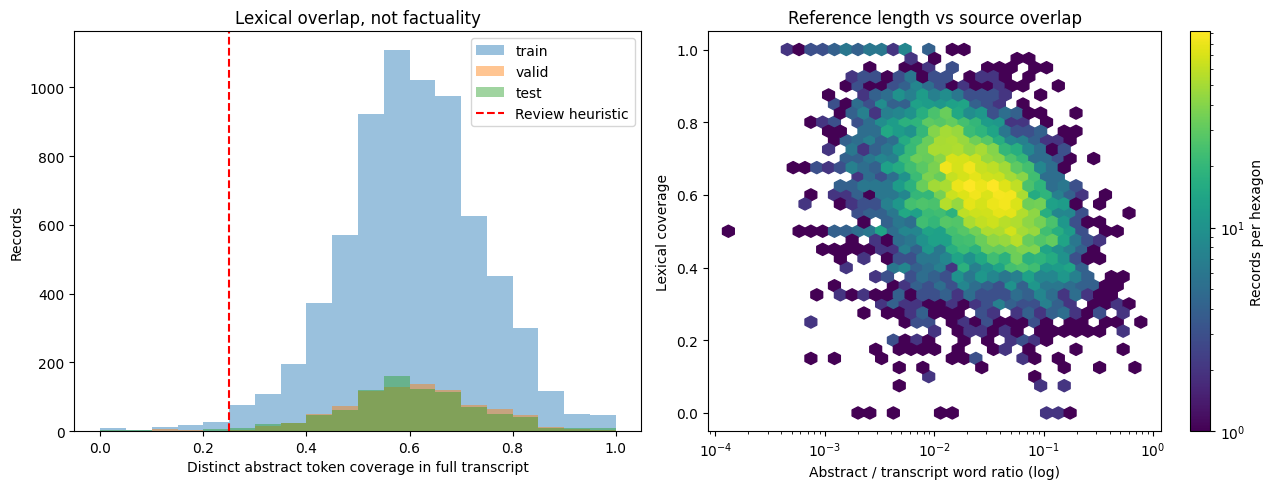

,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
test,879.0,0.600508,0.141423,0.0,0.516129,0.600000,0.688707,1.0
train,7003.0,0.603029,0.136478,0.0,0.517241,0.606061,0.692308,1.0
valid,887.0,0.604106,0.135325,0.1,0.519000,0.611111,0.694118,1.0


Rows plotted in ratio/coverage chart: 8769 / 8769


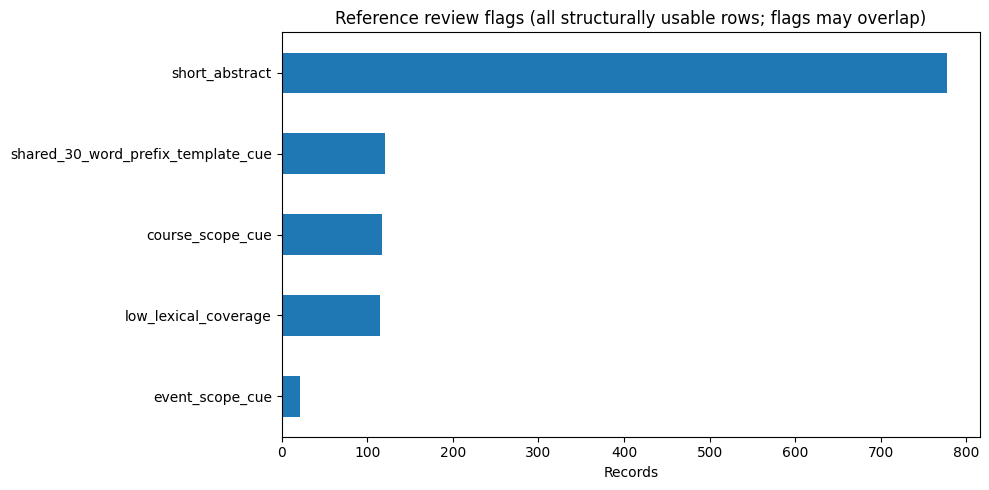

In [8]:
# New figures and tables use the same denominators as the displayed pool.
nonempty_count = int(reference_df['normalized_abstract_sha256'].ne('').sum())
funnel = pd.Series([cohort['source_count'],len(reference_df),nonempty_count,len(pool_df)],
    index=['Source rows','Structurally usable','Nonempty abstract','Unique abstract pool'])
fig, axes = plt.subplots(1,3,figsize=(17,5))
funnel.plot.barh(ax=axes[0], color='steelblue'); axes[0].invert_yaxis()
axes[0].set_title('Candidate flow (records)')
for i,value in enumerate(funnel): axes[0].text(value,i,f' {value:,}',va='center')
subject_counts = pool_df['subject'].fillna('').replace('', '(missing)').value_counts()
subject_counts.head(12).sort_values().plot.barh(ax=axes[1])
axes[1].set_title('Top exact subject labels in pool')
genre_counts = pool_df['genre'].fillna('').replace('', '(missing)').value_counts()
genre_counts.sort_values().plot.barh(ax=axes[2]); axes[2].set_title('All exact genre labels in pool')
show_figure(fig)
display(pd.DataFrame({'records':subject_counts, 'percent':100*subject_counts/max(1,len(pool_df))}))
display(genre_counts.rename('records').to_frame())
fig, axes = plt.subplots(1,2,figsize=(13,5))
for split in splits:
    values=pool_df.loc[pool_df['split'].eq(split),'reference_token_coverage'].dropna()
    axes[0].hist(values,bins=20,range=(0,1),alpha=.45,label=split)
axes[0].axvline(LOW_LEXICAL_COVERAGE,color='red',linestyle='--',label='Review heuristic')
axes[0].set_xlabel('Distinct abstract token coverage in full transcript')
axes[0].set_ylabel('Records'); axes[0].legend(); axes[0].set_title('Lexical overlap, not factuality')
ratio = pool_df['abstract_words']/pool_df['transcript_words'].replace(0,float('nan'))
valid=ratio.gt(0)&pool_df['reference_token_coverage'].notna()
if valid.any():
    density=axes[1].hexbin(ratio[valid],pool_df.loc[valid,'reference_token_coverage'],
        xscale='log',gridsize=35,mincnt=1,bins='log')
    fig.colorbar(density,ax=axes[1],label='Records per hexagon')
axes[1].set_xlabel('Abstract / transcript word ratio (log)')
axes[1].set_ylabel('Lexical coverage'); axes[1].set_title('Reference length vs source overlap')
show_figure(fig)
display(pool_df.groupby('split')['reference_token_coverage'].describe())
print('Rows plotted in ratio/coverage chart:', int(valid.sum()), '/', len(pool_df))
if reference_flag_counts:
    fig,ax=plt.subplots(figsize=(10,5))
    pd.Series(reference_flag_counts).sort_values().plot.barh(ax=ax)
    ax.set_title("Reference review flags (all structurally usable rows; flags may overlap)")
    ax.set_xlabel("Records")
    show_figure(fig)


### Duyệt mẫu đa dạng và các trường hợp đáng ngờ

`REVIEW_SAMPLE_SIZE` chỉ giới hạn **mẫu đọc EDA**, không giới hạn benchmark. Thuật toán xác định ưu tiên các nhãn hiếm theo split/genre/subject/thời lượng, rồi cờ cảnh báo; đây không phải mẫu ngẫu nhiên để ước lượng tỷ lệ lỗi toàn corpus. Bảng riêng bên dưới vẫn chứa tất cả bản ghi có cờ.

Đọc abstract đầy đủ cùng tối đa hai đoạn transcript khớp từ cao. Có thể tăng `REVIEW_DISPLAY_LIMIT` hoặc lọc `reference_df` theo ID. Nếu đoạn trích chưa đủ, mở source URL hoặc đối chiếu transcript gốc đầy đủ; không suy luận reference đúng từ các đoạn trích này.

In [9]:
REVIEW_SAMPLE_SIZE = 100
REVIEW_DISPLAY_LIMIT = 20
review_sample = detail_ns['diverse_review_sample'](pool_df.to_dict('records'), REVIEW_SAMPLE_SIZE)
sample_df = pd.DataFrame(review_sample, columns=reference_df.columns)
print('Deterministic diversity audit sample:',len(sample_df),'/',len(pool_df))
with pd.option_context('display.max_rows', None, 'display.max_colwidth', None):
    display(sample_df[['split','source_index','doi','genre','subject','duration_minutes',
        'reference_token_coverage','reference_review_flags']])
flagged_df=pool_df.loc[pool_df['reference_review_flags'].map(bool)]
print('All flagged candidate records:',len(flagged_df))
with pd.option_context('display.max_rows', None, 'display.max_colwidth', None):
    display(flagged_df[['split','source_index','doi','reference_review_flags']])
# Show sample marginal coverage so omissions are visible before manual reading.
for field in ['split','genre','subject']:
    table=pool_df[field].fillna('').replace('', '(missing)').value_counts().rename('pool_records').to_frame()
    table['sample_records']=sample_df[field].fillna('').replace('', '(missing)').value_counts().reindex(table.index,fill_value=0)
    print('Review sample coverage:',field); display(table)
for row in review_sample[:REVIEW_DISPLAY_LIMIT]:
    print('\n'+'='*80)
    print('ID:',(row['split'],row['source_index']),'| DOI:',row['doi'])
    print('Source:',row['source_url'],'| Flags:',row['reference_review_flags'])
    print('ABSTRACT (full):\n'+row['abstract_text'])
    print('Unmatched reference tokens:',row['unmatched_reference_tokens'])
    for excerpt in row['matched_source_excerpts']:
        print('TRANSCRIPT excerpt at word',excerpt['start_word'],':\n'+excerpt['text'])
    if not row['matched_source_excerpts']:
        print('No matching excerpt. Inspect the original transcript/source; this is not proof of an incorrect abstract.')

Deterministic diversity audit sample: 100 / 8769


,split,source_index,doi,genre,subject,duration_minutes,reference_token_coverage,reference_review_flags
0,train,6178,10.5446/40029 (DOI),,,59.47,0.526316,[]
1,train,2208,10.5446/54144 (DOI),Lecture\nConference/Talk\nResearch Data\nVideo Abstract,Environmental Sciences / Ecology,23.55,0.342105,[]
2,train,7255,10.5446/51990 (DOI),Lecture\nConference/Talk,History,20.46,0.700000,[short_abstract]
3,valid,252,10.5446/58952 (DOI),Workshop/Interactive Format\nLecture,Computer Science\nMathematics\nEngineering,47.98,0.704225,[]
4,train,3213,10.5446/49805 (DOI),Conference/Talk,Earth Sciences,99.78,0.727273,[]
5,train,7087,10.5446/50062 (DOI),Conference/Talk,Life Sciences\nChemistry\nEarth Sciences,6.08,0.392857,[]
6,train,3777,10.5446/36582 (DOI),Conference/Talk,Chemistry\nEngineering,25.07,0.692308,[short_abstract]
7,train,5641,10.5446/38509 (DOI),Conference/Talk,Earth Sciences\nComputer Science,16.80,0.750000,[short_abstract]
8,train,5588,10.5446/55098 (DOI),Conference/Talk,Philosophy,46.60,0.496124,[]
9,train,5779,10.5446/47899 (DOI),Conference/Talk,Information Science\nMathematics,15.42,0.823529,[]


All flagged candidate records: 900


,split,source_index,doi,reference_review_flags
40,train,40,10.5446/43146 (DOI),[course_scope_cue]
51,train,51,10.5446/49067 (DOI),[short_abstract]
68,train,68,10.5446/40811 (DOI),[short_abstract]
75,train,75,10.5446/18063 (DOI),[short_abstract]
80,train,80,10.5446/33213 (DOI),[event_scope_cue]
91,train,91,10.5446/48154 (DOI),[short_abstract]
102,train,102,10.5446/56646 (DOI),[short_abstract]
124,train,124,10.5446/35915 (DOI),[shared_30_word_prefix_template_cue]
125,train,125,10.5446/50997 (DOI),[short_abstract]
135,train,135,10.5446/49504 (DOI),[short_abstract]


Review sample coverage: split


,pool_records,sample_records
split,,
train,7003,23
valid,887,1
test,879,76


Review sample coverage: genre


,pool_records,sample_records
genre,,
Conference/Talk,7897,58
Lecture,570,30
Webinar/Tutorial,135,3
Workshop/Interactive Format\nLecture,91,3
Conference/Talk\nLecture,28,1
Lecture\nConference/Talk,25,1
Conference/Talk\nWorkshop/Interactive Format,17,1
Conference/Talk\nLecture\nWorkshop/Interactive Format,4,1
Lecture\nConference/Talk\nResearch Data\nVideo Abstract,1,1


Review sample coverage: subject


,pool_records,sample_records
subject,,
Computer Science,7249,36
Mathematics,357,4
Physics,230,10
Information Science,147,1
Mathematics\nPhysics,114,1
Chemistry,109,4
Linguistics,101,10
Economics and Social Sciences,75,4
Engineering,59,1



ID: ('train', 6178) | DOI: 10.5446/40029 (DOI)
Source: https://av.tib.eu/media/40029 | Flags: []
ABSTRACT (full):
In this talk we will explain how some common attacks against vulnerable software work and will explain how the security measures used by the Gentoo Hardened project act against them along with the drawbacks they impose.
Unmatched reference tokens: ['act', 'along', 'common', 'drawbacks', 'gentoo', 'hardened', 'impose', 'measures', 'software']
TRANSCRIPT excerpt at word 0 :
I am Francisco Blas, I come from Spain, he is a Leonid, he comes from Sweden, he is going to be my assistant. You will soon understand what that means. And I'm going to speak about the GEN2 Hardenet. As a side note, please feel free to interrupt me at any moment. And during the questions and answers session at the end of the talk, if anybody has a question, he can try to ask over Twitter or on our IRC channel. And if I manage to read it, I will answer it. That goes for the people on the streams, okay? So,

### Quyết định và danh sách benchmark trong bộ nhớ

Chọn claim **agreement_with_unverified_creator_abstracts_only**. Danh sách dưới đây là ứng viên sau sàng lọc cơ học; trạng thái chưa duyệt được hiển thị rõ, không giả thành nhãn đúng/sai. Không bắt buộc duyệt thủ công toàn bộ để báo cáo agreement, nhưng phải công bố các cảnh báo và giới hạn reference.

Có thể ghi quyết định thủ công vào `MANUAL_REFERENCE_DECISIONS` trong ô dưới rồi chạy lại ô đó và lưu notebook. Mỗi quyết định cần ID, `keep`/`exclude` và lý do. Không tự phục hồi reference rỗng/trùng. Kết quả không chứng minh factuality, độ đúng ASR, độ đa dạng hình ảnh hoặc holdout chưa xem. Nếu có training/tuning trên TIB, cần xử lý nhóm nguồn riêng trước khi đánh giá.
Bảng quyết định cuối cùng hiển thị **mọi ID text-usable** cùng trạng thái giữ/loại, đã/chưa duyệt và lý do, không rút gọn số dòng. Lưu notebook kèm output sau khi chạy để giữ toàn bộ ledger. Các ID bị loại cấu trúc ở bảng `excluded_rows` phía trên.


In [10]:
# Record manual EDA judgments here; no separate receipt file.
# Example syntax only: ('valid', SOURCE_INDEX): {'decision':'exclude', 'reason':'Observed scope mismatch ...'}
MANUAL_REFERENCE_DECISIONS = {}
CLAIM = 'agreement_with_unverified_creator_abstracts_only'
lookup={(row['split'],row['source_index']):row for row in reference_rows}
for key, judgment in MANUAL_REFERENCE_DECISIONS.items():
    if key not in lookup or judgment.get('decision') not in {'keep','exclude'} or not str(judgment.get('reason','')).strip():
        raise ValueError(f'Invalid manual decision/reason: {key}')
    if judgment['decision']=='keep' and not lookup[key]['broad_pool_candidate']:
        raise ValueError(f'Cannot restore a mechanically excluded reference: {key}')
decision_rows=[]
for row in reference_rows:
    key=(row['split'],row['source_index']); manual=MANUAL_REFERENCE_DECISIONS.get(key)
    included=row['broad_pool_candidate'] and (manual is None or manual['decision']=='keep')
    decision_rows.append({'split':key[0],'source_index':key[1],'doi':row['doi'],
        'included_for_limited_agreement':included,
        'manual_review_status':'reviewed' if manual else 'not_reviewed',
        'manual_reason':manual['reason'] if manual else '',
        'mechanical_exclusions':row['reference_exclusion_reasons'],
        'review_flags':row['reference_review_flags']})
benchmark_decision_df=pd.DataFrame(decision_rows)
benchmark_candidate_ids=[(row['split'],row['source_index']) for row in decision_rows if row['included_for_limited_agreement']]
print('Claim:',CLAIM,'| candidate IDs:',len(benchmark_candidate_ids),'| no benchmark-size cap')
print('Manual judgments:',len(MANUAL_REFERENCE_DECISIONS))
with pd.option_context('display.max_rows', None, 'display.max_colwidth', None):
    display(benchmark_decision_df)
print('IDs available in benchmark_candidate_ids; decisions/reasons in benchmark_decision_df.')
reviewed=len(MANUAL_REFERENCE_DECISIONS)
flagged=int(pool_df['reference_review_flags'].map(bool).sum())
dominant=subject_counts.index[0] if len(subject_counts) else '(empty pool)'
share=100*subject_counts.iloc[0]/len(pool_df) if len(pool_df) else 0
summary=(f'**Reference EDA:** {len(reference_df):,} structurally usable rows screened; '
    f'{len(pool_df):,} unique nonempty abstract candidates; {flagged:,} candidates flagged; '
    f'{reviewed:,} manual decisions recorded. Dominant exact subject: {dominant} ({share:.1f}%). '
    'Report results by genre/subject/duration as well as pooled agreement. '
    'Lexical coverage and matching excerpts do not establish factual support. '
    'Candidate IDs are available; the model/tokenizer/token-budget protocol is not frozen by EDA. '
    'Creator test was read; no unseen-holdout claim. No summarization model was run.')
display(Markdown(summary))

Claim: agreement_with_unverified_creator_abstracts_only | candidate IDs: 8769 | no benchmark-size cap
Manual judgments: 0


,split,source_index,doi,included_for_limited_agreement,manual_review_status,manual_reason,mechanical_exclusions,review_flags
0,train,0,10.5446/18349 (DOI),True,not_reviewed,,[],[]
1,train,1,10.5446/47465 (DOI),True,not_reviewed,,[],[]
2,train,2,10.5446/43826 (DOI),True,not_reviewed,,[],[]
3,train,3,10.5446/42853 (DOI),True,not_reviewed,,[],[]
4,train,4,10.5446/19424 (DOI),True,not_reviewed,,[],[]
5,train,5,10.5446/56663 (DOI),True,not_reviewed,,[],[]
6,train,6,10.14288/1.0398184 (DOI),True,not_reviewed,,[],[]
7,train,7,10.5446/40562 (DOI),True,not_reviewed,,[],[]
8,train,8,10.5446/39718 (DOI),True,not_reviewed,,[],[]
9,train,9,10.5446/45472 (DOI),True,not_reviewed,,[],[]


IDs available in benchmark_candidate_ids; decisions/reasons in benchmark_decision_df.


**Reference EDA:** 9,002 structurally usable rows screened; 8,769 unique nonempty abstract candidates; 900 candidates flagged; 0 manual decisions recorded. Dominant exact subject: Computer Science (82.7%). Report results by genre/subject/duration as well as pooled agreement. Lexical coverage and matching excerpts do not establish factual support. Candidate IDs are available; the model/tokenizer/token-budget protocol is not frozen by EDA. Creator test was read; no unseen-holdout claim. No summarization model was run.